# Phase 2: Exploratory Data Analysis (EDA)
## Intelligent Consumer Complaint Classification & Prioritization Using NLP

**Dataset:** `liri-uzh/cfpb-complaints-mini` (Train: 6,469 rows, Test: 1,635 rows)  
**Target:** Multi-class classification across 7 consumer financial product categories (`label`)

### Objectives of This Notebook
1. **Validate Data Integrity:** Verify shapes, data types, missing values, empty narratives, and schema consistency across `train.csv` and `test.csv` without altering raw files.
2. **Analyze Target Distribution:** Evaluate class balance across the 7 product categories in both splits and assess implications for evaluation metrics.
3. **Examine Text Length & Structural Outliers:** Compute character, word, and sentence length statistics overall and per class.
4. **Explore Vocabulary & N-grams:** Identify overall and class-specific unigrams, bigrams, and trigrams, and inspect TF-IDF feature characteristics (fitted strictly on `train`).
5. **Investigate Duplicates & Train-Test Leakage:** Quantify exact and text-level duplicates within splits and potential overlap/leakage between `train` and `test`.
6. **Assess Text Quality & Linguistic Patterns:** Quantify CFPB redaction tokens (`XXXX`), URLs, monetary/numeric tokens, casing, and boilerplate.
7. **Derive Phase 3 Recommendations:** Formulate evidence-based preprocessing, feature engineering, and baseline model selection strategies.

## 2. Imports and Configuration

We import core data manipulation, visualization, and NLP feature-extraction libraries, set a reproducible random seed, and configure paths relative to the project root.

In [1]:
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from wordcloud import STOPWORDS, WordCloud

warnings.filterwarnings("ignore")

# Reproducibility & Plotting Configuration
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Project Paths
PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data" / "raw").exists():
    PROJECT_ROOT = Path("Experiment_9/complaint-classification").resolve()

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures" / "eda"
REPORTS_DIR = PROJECT_ROOT / "reports"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root : {PROJECT_ROOT}")
print(f"Raw Data Dir : {DATA_RAW_DIR}")
print(f"Figures Dir  : {FIGURES_DIR}")

Project Root : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification
Raw Data Dir : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\data\raw
Figures Dir  : D:\SEM 7\CLNLP\LAB\Experiment_9\complaint-classification\reports\figures\eda


## 3. Dataset Loading and Validation

We load `data/raw/train.csv` and `data/raw/test.csv` in read-only mode and verify shapes, column names, data types, missing values, empty narratives, unique labels, unique narratives, and duplicate counts.

In [2]:
train_path = DATA_RAW_DIR / "train.csv"
test_path = DATA_RAW_DIR / "test.csv"

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

def validate_split(df: pd.DataFrame, name: str) -> dict:
    empty_text = (df["text"].isnull() | (df["text"].astype(str).str.strip() == "")).sum()
    return {
        "Split": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Missing Values": int(df.isnull().sum().sum()),
        "Empty Narratives": int(empty_text),
        "Unique Labels": int(df["label"].nunique()),
        "Unique Narratives": int(df["text"].nunique()),
        "Exact Duplicate Rows": int(df.duplicated().sum()),
        "Duplicate Narratives": int(df["text"].duplicated().sum()),
    }

validation_df = pd.DataFrame([
    validate_split(df_train, "Train"),
    validate_split(df_test, "Test"),
])
display(validation_df)

print("\nColumn Data Types (Train):")
print(df_train.dtypes)
print("\nUnique Labels (Train):", sorted(df_train["label"].unique().tolist()))
print("Unique Labels (Test) :", sorted(df_test["label"].unique().tolist()))

,Split,Rows,Columns,Missing Values,Empty Narratives,Unique Labels,Unique Narratives,Exact Duplicate Rows,Duplicate Narratives
0,Train,6469,3,0,0,7,6364,102,105
1,Test,1635,3,0,0,7,1635,0,0



Column Data Types (Train):
text           object
label          object
product_raw    object
dtype: object

Unique Labels (Train): ['bank_account', 'credit_card', 'credit_reporting', 'debt_collection', 'money_transfer', 'mortgage', 'student_loan']
Unique Labels (Test) : ['bank_account', 'credit_card', 'credit_reporting', 'debt_collection', 'money_transfer', 'mortgage', 'student_loan']


### Representative Complaint Examples by Class
Let us inspect one representative sample from each of the 7 target classes in the training set to understand domain tone, structure, and redaction conventions.

In [3]:
for label in sorted(df_train["label"].unique()):
    sample = df_train[df_train["label"] == label].iloc[0]
    snippet = sample["text"][:320].replace("\n", " ")
    print(f"[{label}] (product_raw='{sample['product_raw']}')")
    print(f"  {snippet}...\n")

[bank_account] (product_raw='Checking or savings account')
  on XX/XX/XXXX, I visited Wells Fargo to open a CD and new checking account, when I checked my Wells Fargo App, I noticed that on XXXX of the business account I have custody of for an organization ( XXXX XXXX XXXX XXXX XXXX ), has a balance that seemed low. When I checked the transactions, I found an unauthorized XXXX p...

[credit_card] (product_raw='Credit card')
  Subject : Complaint Regarding Recent Credit Application Decision for American Express Gold Card Dear Consumer Financial Protection Bureau, I am writing to express my deep concerns regarding the recent decision on my credit application for the American Express Gold Card. I am the applicant in question, and I am reaching...

[credit_reporting] (product_raw='Credit reporting, credit repair services, or other personal consumer reports')
  I am a victim of identity theft. I have sent the correct paperwork per the FCRA to fix my credit reports. The reporting agencies ar

## 4. Dataset Overview and Schema

Let us verify the 1-to-1 mapping between `label` (normalized target) and `product_raw` (original CFPB product category) across both splits.

In [4]:
train_mapping = df_train.groupby("label")["product_raw"].unique().apply(list)
test_mapping = df_test.groupby("label")["product_raw"].unique().apply(list)

schema_map_df = pd.DataFrame({
    "Train product_raw": train_mapping,
    "Test product_raw": test_mapping,
})
display(schema_map_df)

,Train product_raw,Test product_raw
label,,
bank_account,[Checking or savings account],[Checking or savings account]
credit_card,"[Credit card, Prepaid card, Credit card or pre...","[Credit card or prepaid card, Prepaid card, Cr..."
credit_reporting,"[Credit reporting, credit repair services, or ...","[Credit reporting, credit repair services, or ..."
debt_collection,[Debt collection],[Debt collection]
money_transfer,"[Money transfer, virtual currency, or money se...","[Money transfer, virtual currency, or money se..."
mortgage,[Mortgage],[Mortgage]
student_loan,[Student loan],[Student loan]


**Observation:** Every `label` maps cleanly to its corresponding `product_raw` value(s) without ambiguity. The `text` column contains the consumer complaint narrative, `label` is our 7-class classification target, and `product_raw` is the raw CFPB product string.

## 5. Target Class Distribution

We examine the exact counts and percentages of all seven classes across `train` and `test` to assess class balance and split stratification.

,Train Count,Train %,Test Count,Test %,Total Count,Total %
label,,,,,,
bank_account,960,14.84,240,14.68,1200,14.81
credit_card,862,13.33,219,13.39,1081,13.34
credit_reporting,819,12.66,216,13.21,1035,12.77
debt_collection,948,14.65,240,14.68,1188,14.66
money_transfer,960,14.84,240,14.68,1200,14.81
mortgage,960,14.84,240,14.68,1200,14.81
student_loan,960,14.84,240,14.68,1200,14.81


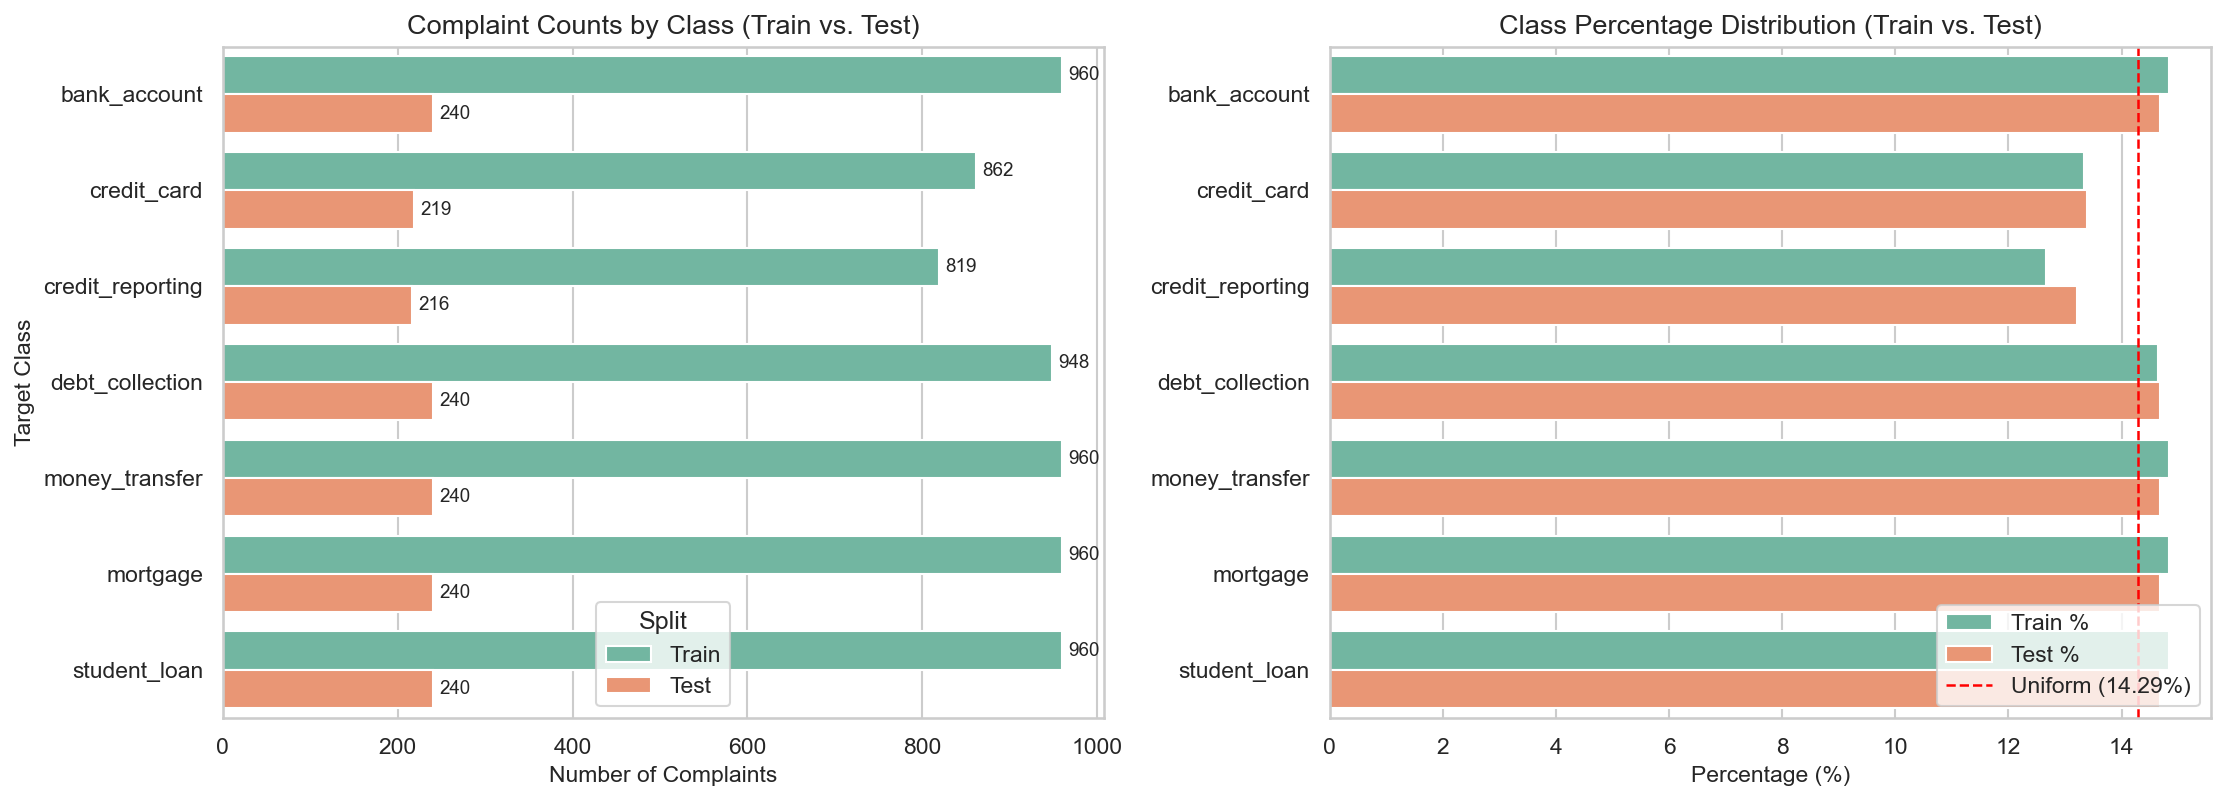

In [5]:
train_counts = df_train["label"].value_counts().sort_index()
test_counts = df_test["label"].value_counts().sort_index()
total_counts = train_counts + test_counts

dist_df = pd.DataFrame({
    "Train Count": train_counts,
    "Train %": (train_counts / len(df_train) * 100).round(2),
    "Test Count": test_counts,
    "Test %": (test_counts / len(df_test) * 100).round(2),
    "Total Count": total_counts,
    "Total %": (total_counts / (len(df_train) + len(df_test)) * 100).round(2),
})
display(dist_df)

# Visualization: Count Plot & Percentage Comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: Grouped Count Plot
plot_data = pd.concat([
    df_train[["label"]].assign(Split="Train"),
    df_test[["label"]].assign(Split="Test")
])
order = sorted(df_train["label"].unique())
sns.countplot(data=plot_data, y="label", hue="Split", order=order, ax=axes[0], palette="Set2")
axes[0].set_title("Complaint Counts by Class (Train vs. Test)")
axes[0].set_xlabel("Number of Complaints")
axes[0].set_ylabel("Target Class")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fontsize=9)

# Right: Percentage Distribution Comparison
pct_melt = dist_df[["Train %", "Test %"]].reset_index().melt(
    id_vars="label", var_name="Split", value_name="Percentage"
)
sns.barplot(data=pct_melt, y="label", x="Percentage", hue="Split", order=order, ax=axes[1], palette="Set2")
axes[1].set_title("Class Percentage Distribution (Train vs. Test)")
axes[1].set_xlabel("Percentage (%)")
axes[1].set_ylabel("")
axes[1].axvline(100 / 7, color="red", linestyle="--", linewidth=1.2, label="Uniform (14.29%)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_target_class_distribution.png", bbox_inches="tight")
plt.show()

**Observations on Class Balance:**
- The dataset is **well-balanced** across all 7 classes (`~12.7%` to `~14.8%` per class, close to a uniform `14.29%` split).
- Four classes (`bank_account`, `money_transfer`, `mortgage`, `student_loan`) have exactly `960` training and `240` test samples each.
- `credit_reporting` (`819` train / `216` test, `12.77%` total) and `credit_card` (`862` train / `219` test, `13.34%` total) are slightly smaller, but not severely underrepresented.
- Train and test proportions are closely stratified (`<0.6%` difference per class).
- **Metric Implication:** Because classes are nearly balanced, both **Accuracy** and **Macro-F1** are informative; we should report **Macro-F1** alongside per-class Precision/Recall/F1 to ensure strong performance on `credit_reporting` and `credit_card` as well.

## 6. Text Length Analysis

We compute four structural length metrics for every complaint in `train` and `test`:
- **Character count** (`char_count`)
- **Word count** (`word_count`)
- **Sentence count** (`sentence_count`, estimated via sentence-ending punctuation `[.!?]+`)
- **Average word length** (`avg_word_length`)

*Note: We do not remove or truncate long complaints in this exploratory phase.*

In [6]:
def add_length_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    texts = out["text"].astype(str)
    out["char_count"] = texts.str.len()
    words_list = texts.str.split()
    out["word_count"] = words_list.str.len()
    out["sentence_count"] = texts.apply(
        lambda t: max(1, len([s for s in re.split(r"[.!?]+", t) if s.strip()]))
    )
    out["avg_word_length"] = texts.apply(
        lambda t: np.mean([len(w) for w in t.split()]) if t.split() else 0.0
    )
    return out

train_len = add_length_features(df_train)
test_len = add_length_features(df_test)

cols_to_summarize = ["char_count", "word_count", "sentence_count", "avg_word_length"]
percentiles = [0.25, 0.5, 0.75, 0.9, 0.95, 0.99]

print("Train Split Length Statistics:")
display(train_len[cols_to_summarize].describe(percentiles=percentiles).round(2))

print("Test Split Length Statistics:")
display(test_len[cols_to_summarize].describe(percentiles=percentiles).round(2))

Train Split Length Statistics:


,char_count,word_count,sentence_count,avg_word_length
count,6469.00,6469.00,6469.00,6469.00
mean,1244.81,222.10,12.22,4.58
std,1519.52,266.45,13.93,0.41
min,21.00,3.00,1.00,2.83
25%,449.00,81.00,5.00,4.30
50%,849.00,153.00,9.00,4.55
75%,1526.00,273.00,15.00,4.82
90%,2542.00,448.20,24.20,5.12
95%,3507.00,617.80,33.00,5.29
99%,6778.64,1194.52,62.00,5.68


Test Split Length Statistics:


,char_count,word_count,sentence_count,avg_word_length
count,1635.00,1635.00,1635.00,1635.00
mean,1239.10,221.78,12.37,4.58
std,1482.43,263.91,13.61,0.42
min,27.00,4.00,1.00,3.13
25%,457.00,82.00,5.00,4.28
50%,894.00,162.00,9.00,4.54
75%,1501.00,266.00,16.00,4.81
90%,2409.80,428.00,25.00,5.11
95%,3283.00,594.50,33.00,5.30
99%,6717.70,1285.26,60.32,5.78


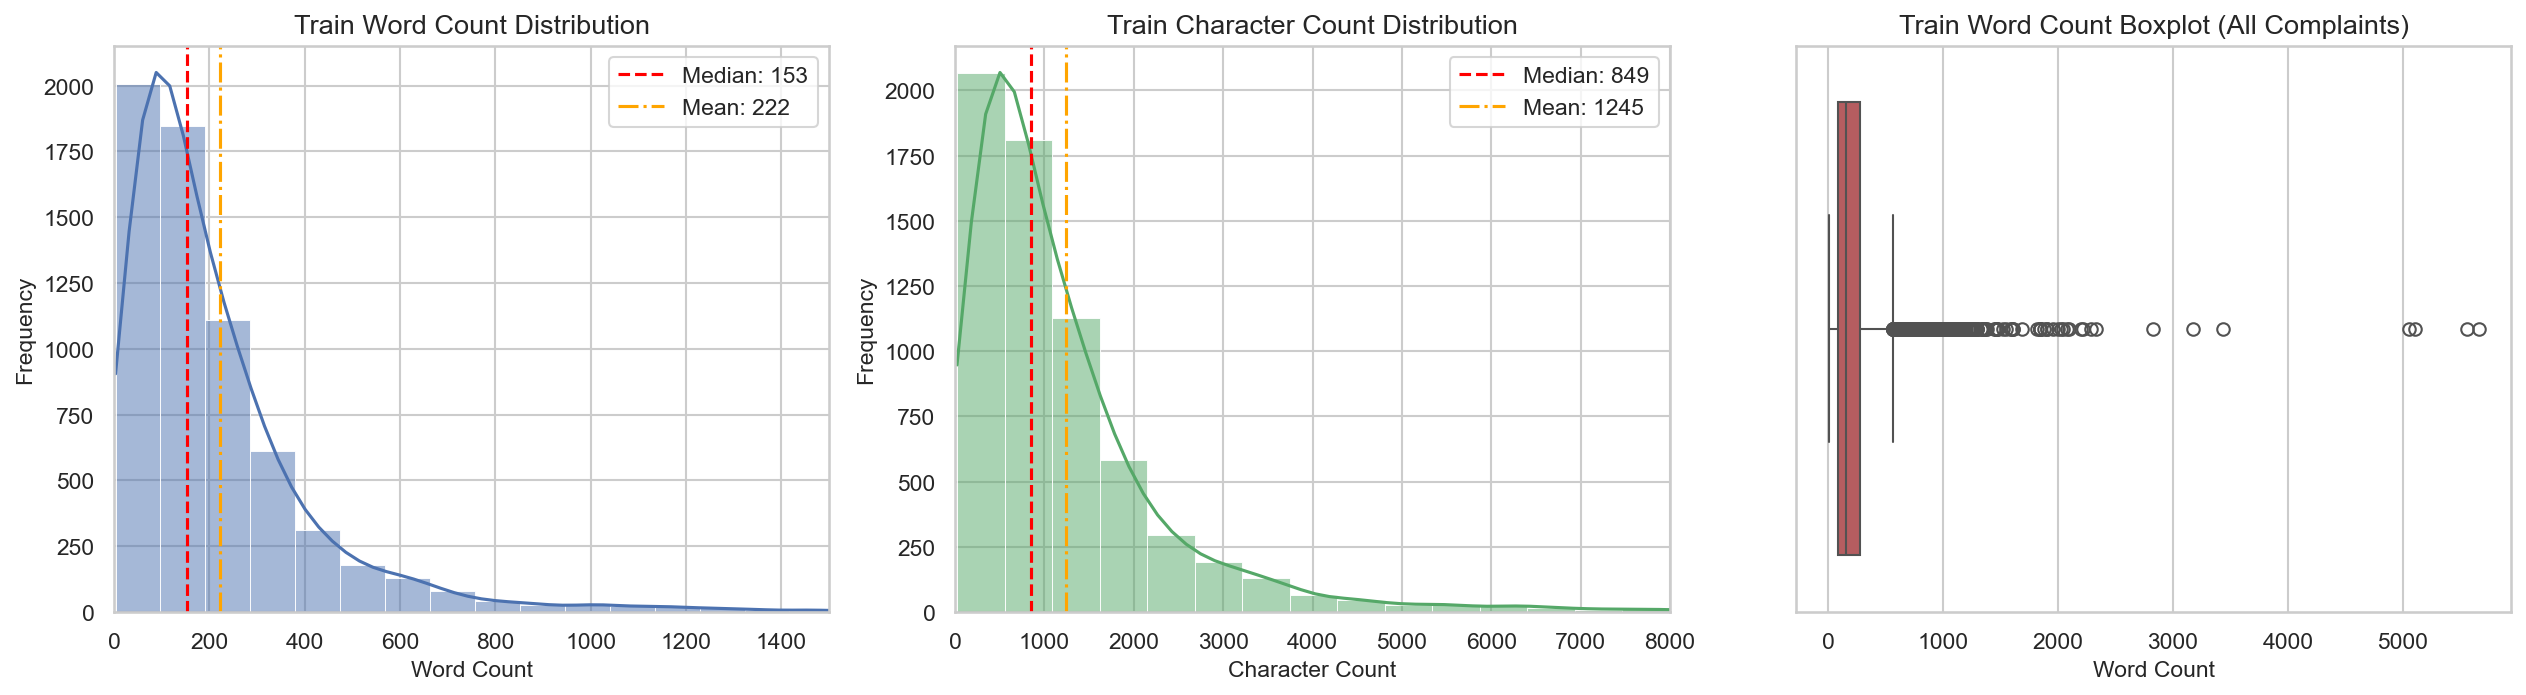

99th percentile word count (train): 1194.5
Number of complaints > 99th percentile: 65 (max = 5659 words)
Complaints > 512 words (typical BERT token budget ~380-400 words): 816 (12.61%)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Word Count Histogram
sns.histplot(train_len["word_count"], bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(train_len["word_count"].median(), color="red", linestyle="--", label=f"Median: {train_len['word_count'].median():.0f}")
axes[0].axvline(train_len["word_count"].mean(), color="orange", linestyle="-.", label=f"Mean: {train_len['word_count'].mean():.0f}")
axes[0].set_title("Train Word Count Distribution")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].set_xlim(0, 1500)
axes[0].legend()

# Character Count Histogram
sns.histplot(train_len["char_count"], bins=60, kde=True, ax=axes[1], color="#55A868")
axes[1].axvline(train_len["char_count"].median(), color="red", linestyle="--", label=f"Median: {train_len['char_count'].median():.0f}")
axes[1].axvline(train_len["char_count"].mean(), color="orange", linestyle="-.", label=f"Mean: {train_len['char_count'].mean():.0f}")
axes[1].set_title("Train Character Count Distribution")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("Frequency")
axes[1].set_xlim(0, 8000)
axes[1].legend()

# Boxplot of Word Counts
sns.boxplot(x=train_len["word_count"], ax=axes[2], color="#C44E52")
axes[2].set_title("Train Word Count Boxplot (All Complaints)")
axes[2].set_xlabel("Word Count")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_text_length_distributions.png", bbox_inches="tight")
plt.show()

# Outlier analysis
p99_words = train_len["word_count"].quantile(0.99)
outliers = train_len[train_len["word_count"] > p99_words]
print(f"99th percentile word count (train): {p99_words:.1f}")
print(f"Number of complaints > 99th percentile: {len(outliers)} (max = {train_len['word_count'].max()} words)")
print(f"Complaints > 512 words (typical BERT token budget ~380-400 words): {(train_len['word_count'] > 400).sum()} ({(train_len['word_count'] > 400).mean()*100:.2f}%)")

**Observations on Text Length:**
- Both character and word counts are **strongly right-skewed**: median word count is `153` in train (`162` in test), while the mean is `~222` words due to a long tail of detailed narratives.
- The 95th percentile is around `550–600` words, and the 99th percentile exceeds `1,000` words (with extreme outliers up to `5,659` words in train).
- A substantial fraction of complaints exceed `400` words, meaning transformer models with a `512`-token limit will truncate the tail of long narratives unless head+tail truncation or hierarchical chunking is used.

## 7. Class-Wise Text Length Analysis

Do certain financial complaint categories (e.g., `mortgage` or `credit_reporting`) tend to produce longer, more detailed narratives than others? Let us inspect class-wise statistics and distributions.

,Count,Mean,Median,Std,Min,P95,Max
label,,,,,,,
mortgage,960,286.13,200.5,341.52,9,794.10,5557
money_transfer,960,225.51,167.5,232.67,6,620.15,3175
bank_account,960,227.39,164.0,227.93,7,598.20,2197
student_loan,960,210.37,164.0,174.53,9,544.25,1457
credit_card,862,186.14,136.0,184.06,6,496.85,1610
debt_collection,948,193.42,133.0,245.72,5,517.65,5102
credit_reporting,819,221.67,109.0,389.44,3,792.00,5659


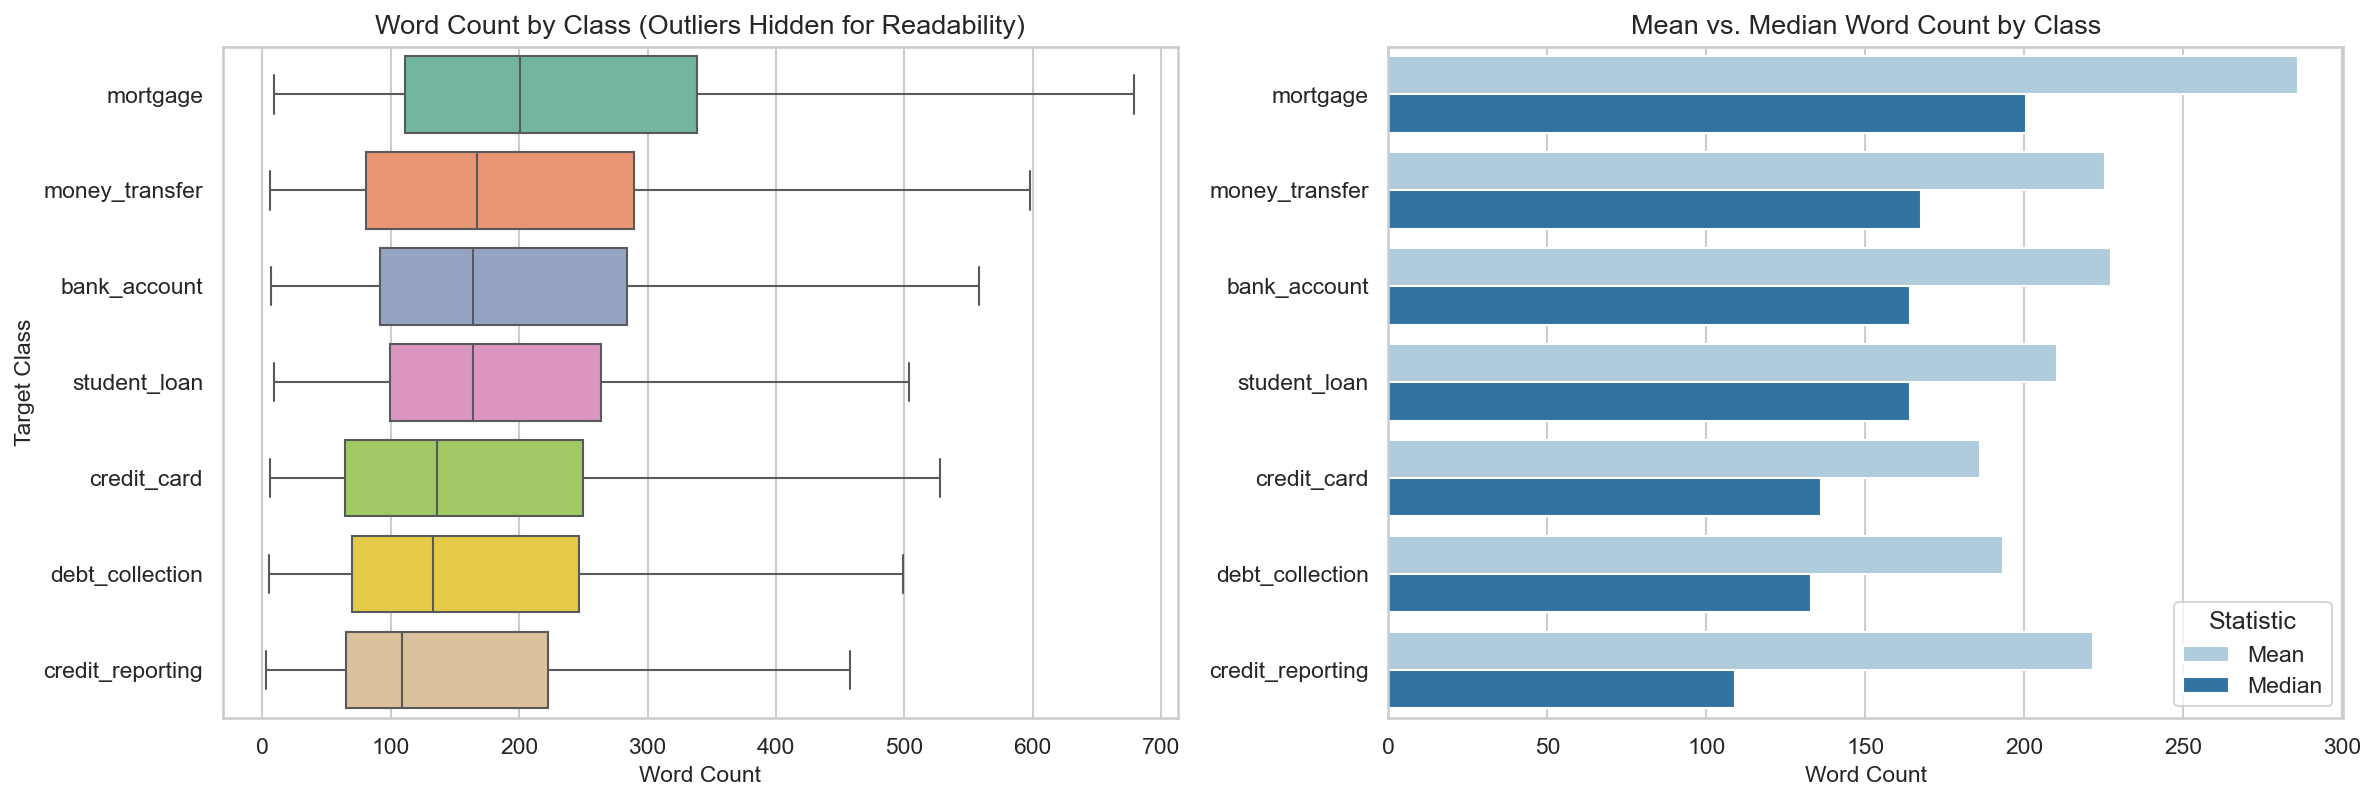

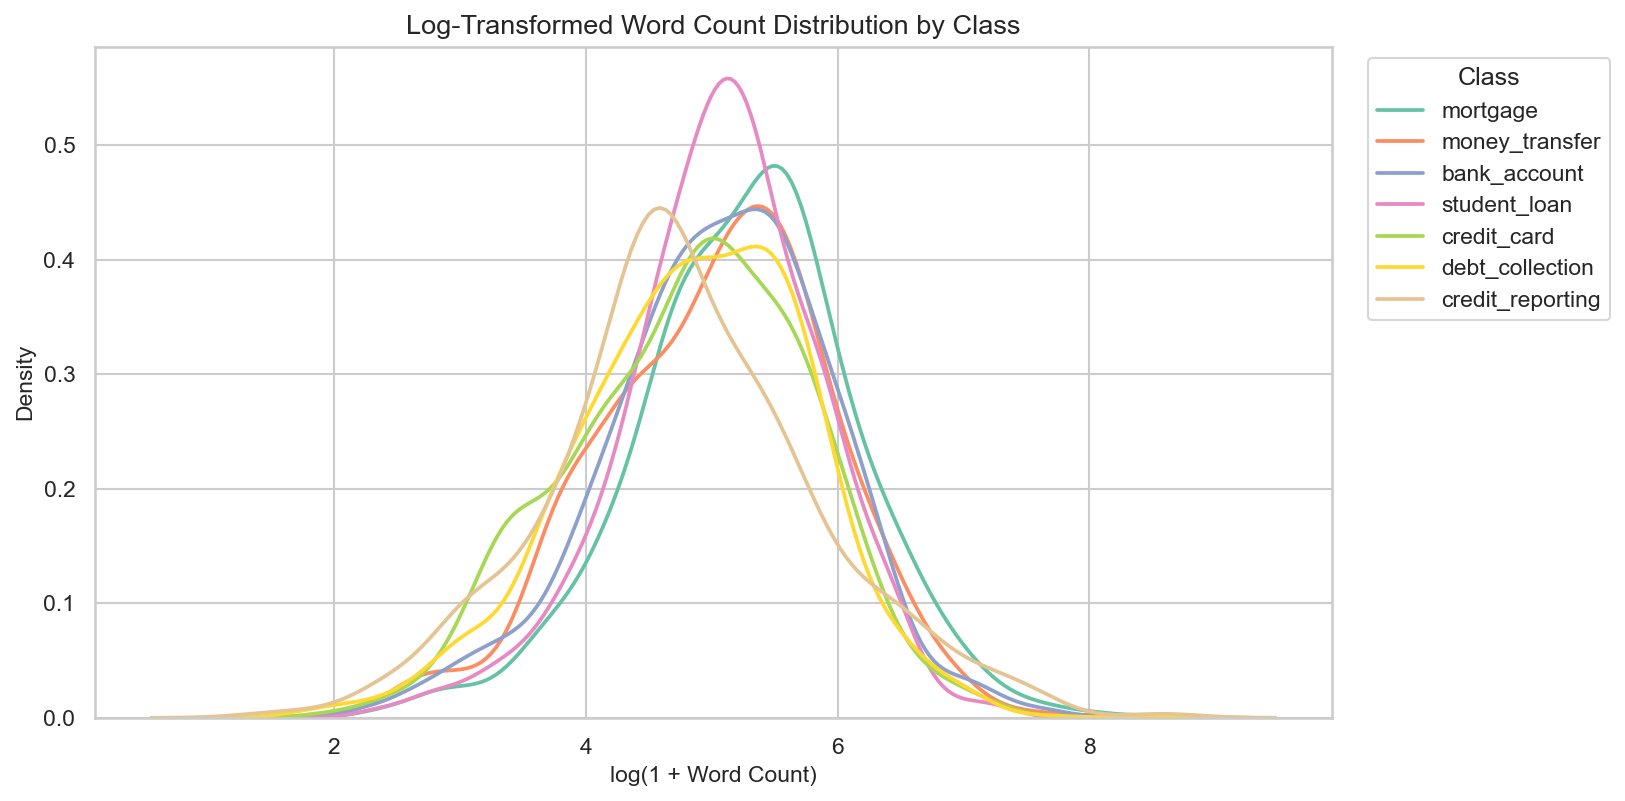

In [8]:
class_len_stats = train_len.groupby("label")["word_count"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std="std",
    Min="min",
    P95=lambda x: np.percentile(x, 95),
    Max="max",
).round(2).sort_values("Median", ascending=False)
display(class_len_stats)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

order_by_med = class_len_stats.index.tolist()
sns.boxplot(data=train_len, y="label", x="word_count", order=order_by_med, ax=axes[0], showfliers=False, palette="Set2")
axes[0].set_title("Word Count by Class (Outliers Hidden for Readability)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Target Class")

mean_med_melt = class_len_stats[["Mean", "Median"]].reset_index().melt(
    id_vars="label", var_name="Statistic", value_name="Words"
)
sns.barplot(data=mean_med_melt, y="label", x="Words", hue="Statistic", order=order_by_med, ax=axes[1], palette="Paired")
axes[1].set_title("Mean vs. Median Word Count by Class")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_classwise_text_length.png", bbox_inches="tight")
plt.show()

# Density plot of log-scaled word count by class
plt.figure(figsize=(11, 5.5))
for lbl in order_by_med:
    subset = np.log1p(train_len[train_len["label"] == lbl]["word_count"])
    sns.kdeplot(subset, label=lbl, linewidth=1.8)
plt.title("Log-Transformed Word Count Distribution by Class")
plt.xlabel("log(1 + Word Count)")
plt.ylabel("Density")
plt.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_length_distribution_by_class.png", bbox_inches="tight")
plt.show()

**Observations on Class-Wise Length:**
- `mortgage` complaints tend to be the longest (highest median and mean word counts), reflecting complex multi-step servicing, escrow, and foreclosure histories.
- `debt_collection` and `credit_reporting` tend to have shorter median narratives, though all classes exhibit right-skewed distributions with long-tail outliers.
- Because the length distributions overlap heavily across all 7 classes, text length alone is a weak predictor, though it may provide a minor auxiliary signal.

## 8. Word Frequency Analysis

We compare:
1. **Raw word frequencies** (including English stopwords and redaction tokens like `xxxx`).
2. **Cleaned exploratory word frequencies** (lowercased, alphabetic tokens `>= 2` chars, English stopwords and `x+` redactions removed).

This illustrates why raw frequency alone is insufficient to separate classes.

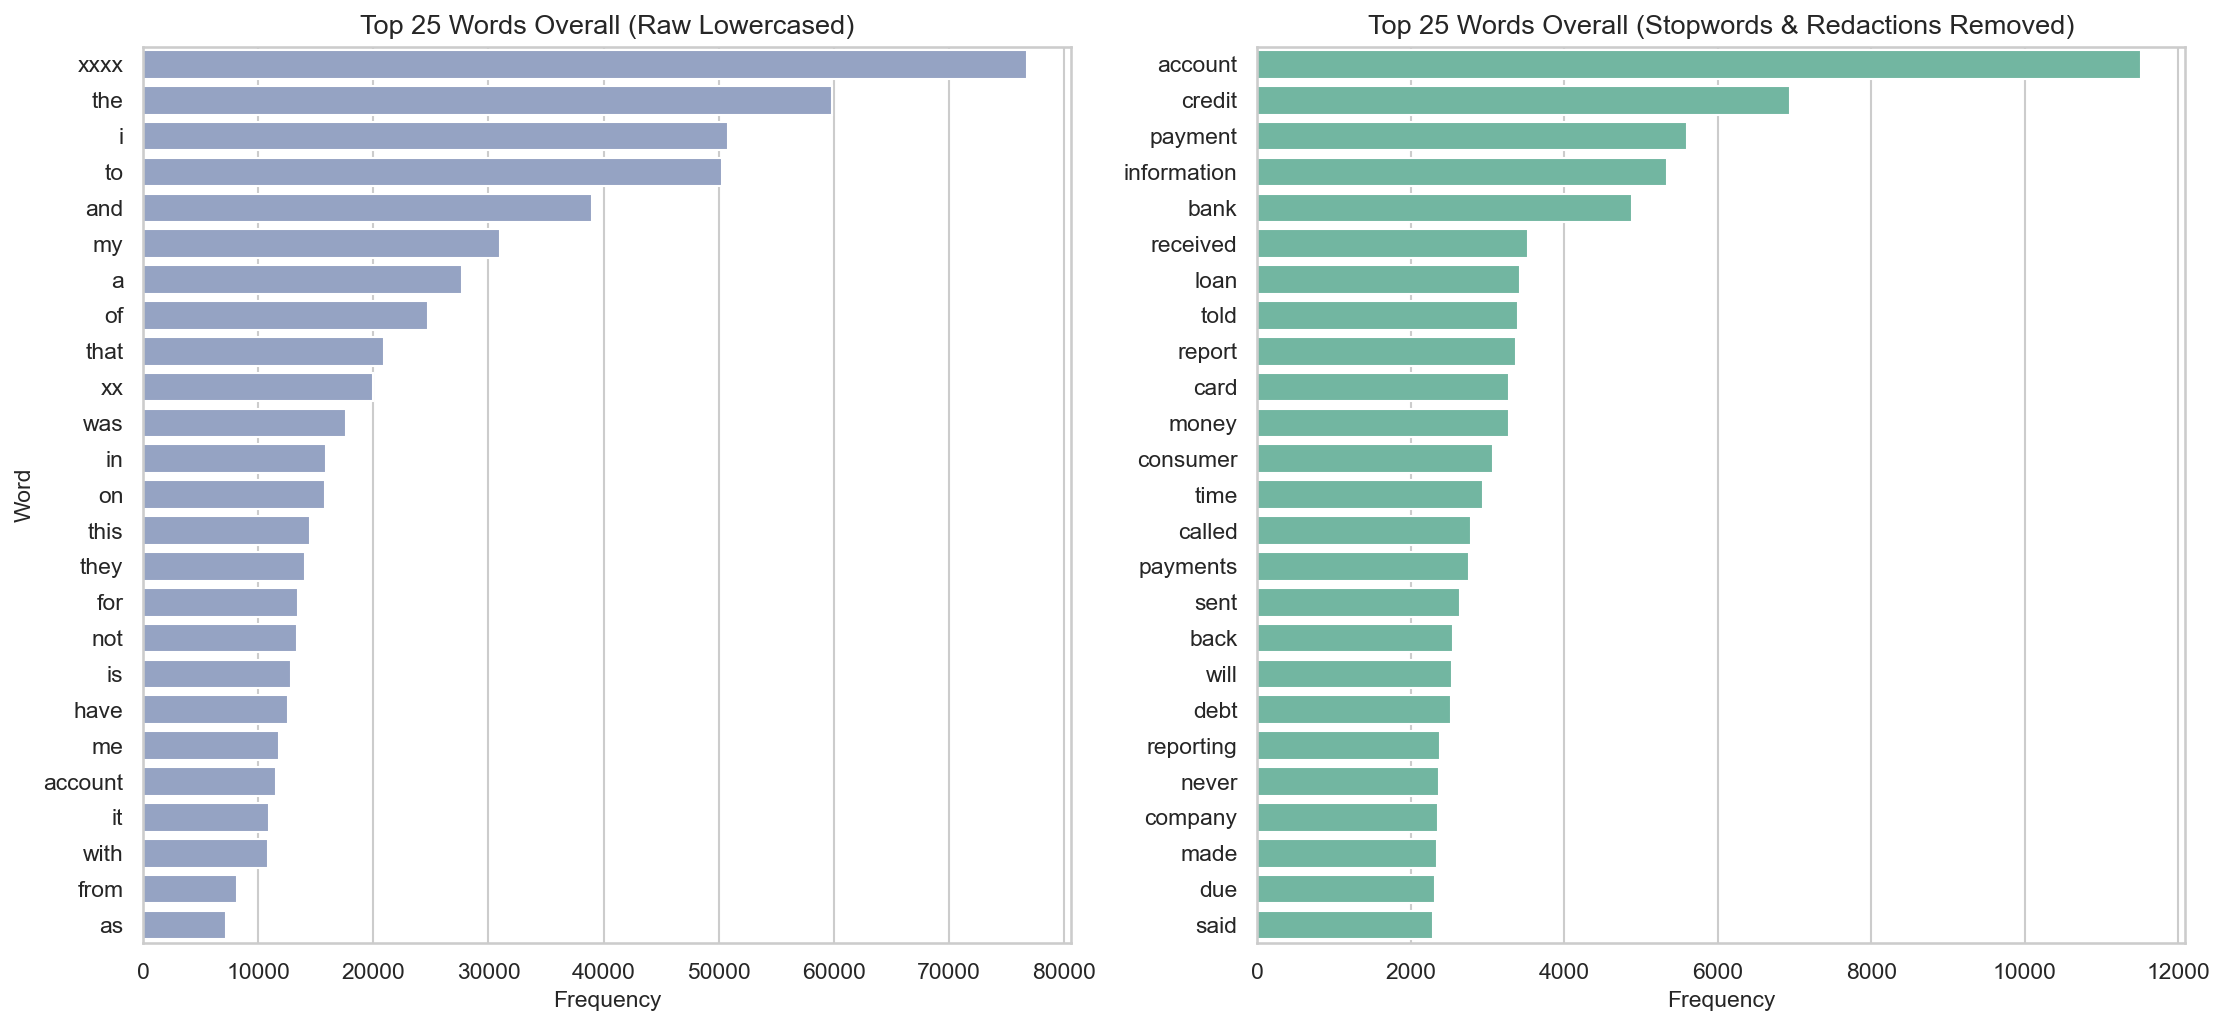

In [9]:
CUSTOM_STOPWORDS = set(STOPWORDS).union({"xxxx", "xxx", "xx", "xxxxx", "xxxxxxxx"})

def tokenize_raw(series):
    tokens = []
    for text in series.astype(str):
        tokens.extend(re.findall(r"[A-Za-z]+", text.lower()))
    return tokens

def tokenize_clean(series):
    tokens = []
    for text in series.astype(str):
        words = re.findall(r"[a-z]{2,}", text.lower())
        tokens.extend([w for w in words if w not in CUSTOM_STOPWORDS and not re.fullmatch(r"x+", w)])
    return tokens

raw_counts = Counter(tokenize_raw(df_train["text"]))
clean_counts = Counter(tokenize_clean(df_train["text"]))

top_raw = pd.DataFrame(raw_counts.most_common(25), columns=["Word", "Count"])
top_clean = pd.DataFrame(clean_counts.most_common(25), columns=["Word", "Count"])

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.barplot(data=top_raw, y="Word", x="Count", ax=axes[0], color="#8DA0CB")
axes[0].set_title("Top 25 Words Overall (Raw Lowercased)")
axes[0].set_xlabel("Frequency")

sns.barplot(data=top_clean, y="Word", x="Count", ax=axes[1], color="#66C2A5")
axes[1].set_title("Top 25 Words Overall (Stopwords & Redactions Removed)")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_word_frequency_overall.png", bbox_inches="tight")
plt.show()

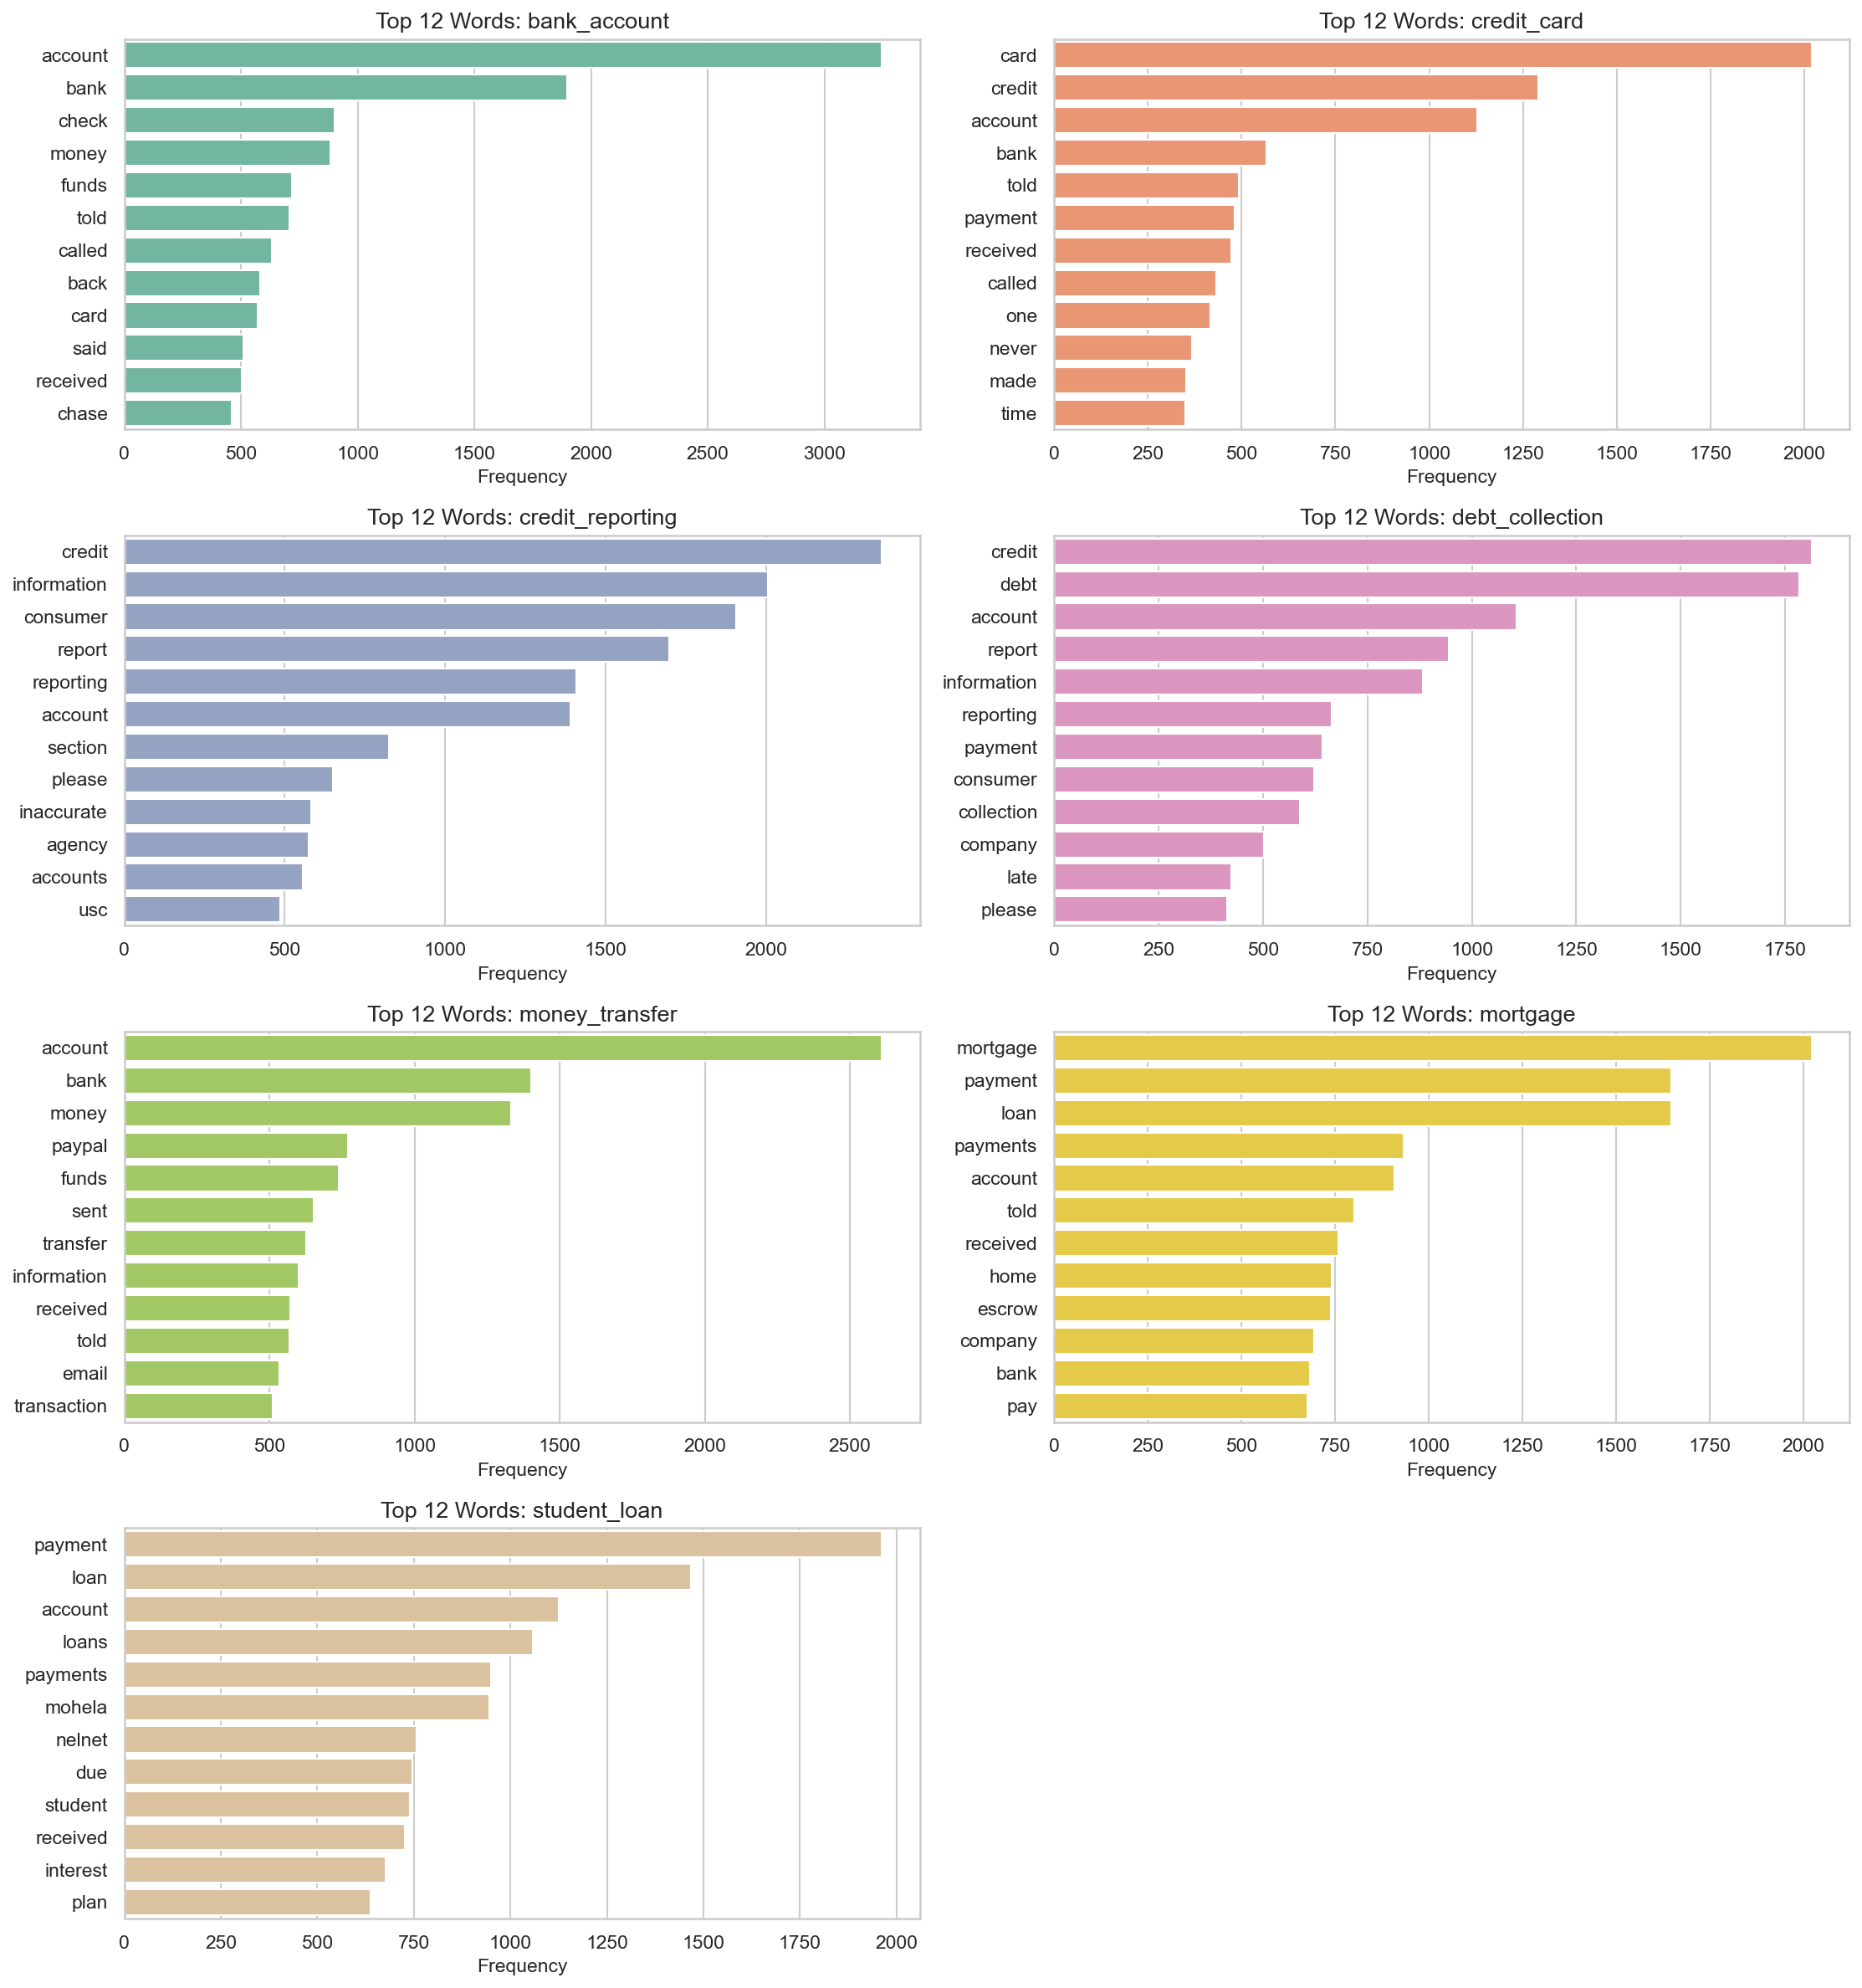

In [10]:
# Top 12 cleaned words per class
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()
classes = sorted(df_train["label"].unique())

for idx, lbl in enumerate(classes):
    cls_tokens = tokenize_clean(df_train[df_train["label"] == lbl]["text"])
    top_cls = pd.DataFrame(Counter(cls_tokens).most_common(12), columns=["Word", "Count"])
    sns.barplot(data=top_cls, y="Word", x="Count", ax=axes[idx], color=sns.color_palette("Set2")[idx])
    axes[idx].set_title(f"Top 12 Words: {lbl}")
    axes[idx].set_xlabel("Frequency")
    axes[idx].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_word_frequency_by_class.png", bbox_inches="tight")
plt.show()

**Observations on Word Frequency:**
- In raw frequencies, English stopwords (`the`, `to`, `and`, `i`, `my`) and redaction tokens (`xxxx`) dominate the top 25 list.
- Even after removing standard stopwords and `xxxx`, generic consumer-complaint terms such as `account`, `payment`, `called`, `told`, `time`, `received`, and `company` appear near the top of **nearly every class**.
- Consequently, raw frequency alone fails to isolate class-discriminative vocabulary; we need **n-grams** and **TF-IDF weighting** to down-weight cross-category boilerplate.

## 9. N-gram Analysis (Unigrams, Bigrams, Trigrams)

We use `CountVectorizer` on the **training set only** with documented exploratory settings:
- `stop_words=list(CUSTOM_STOPWORDS)` (English stopwords + CFPB `x+` redactions)
- `token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"` (alphabetic words of length `>= 2`)
- `min_df=5` (filters rare typos and one-off names)

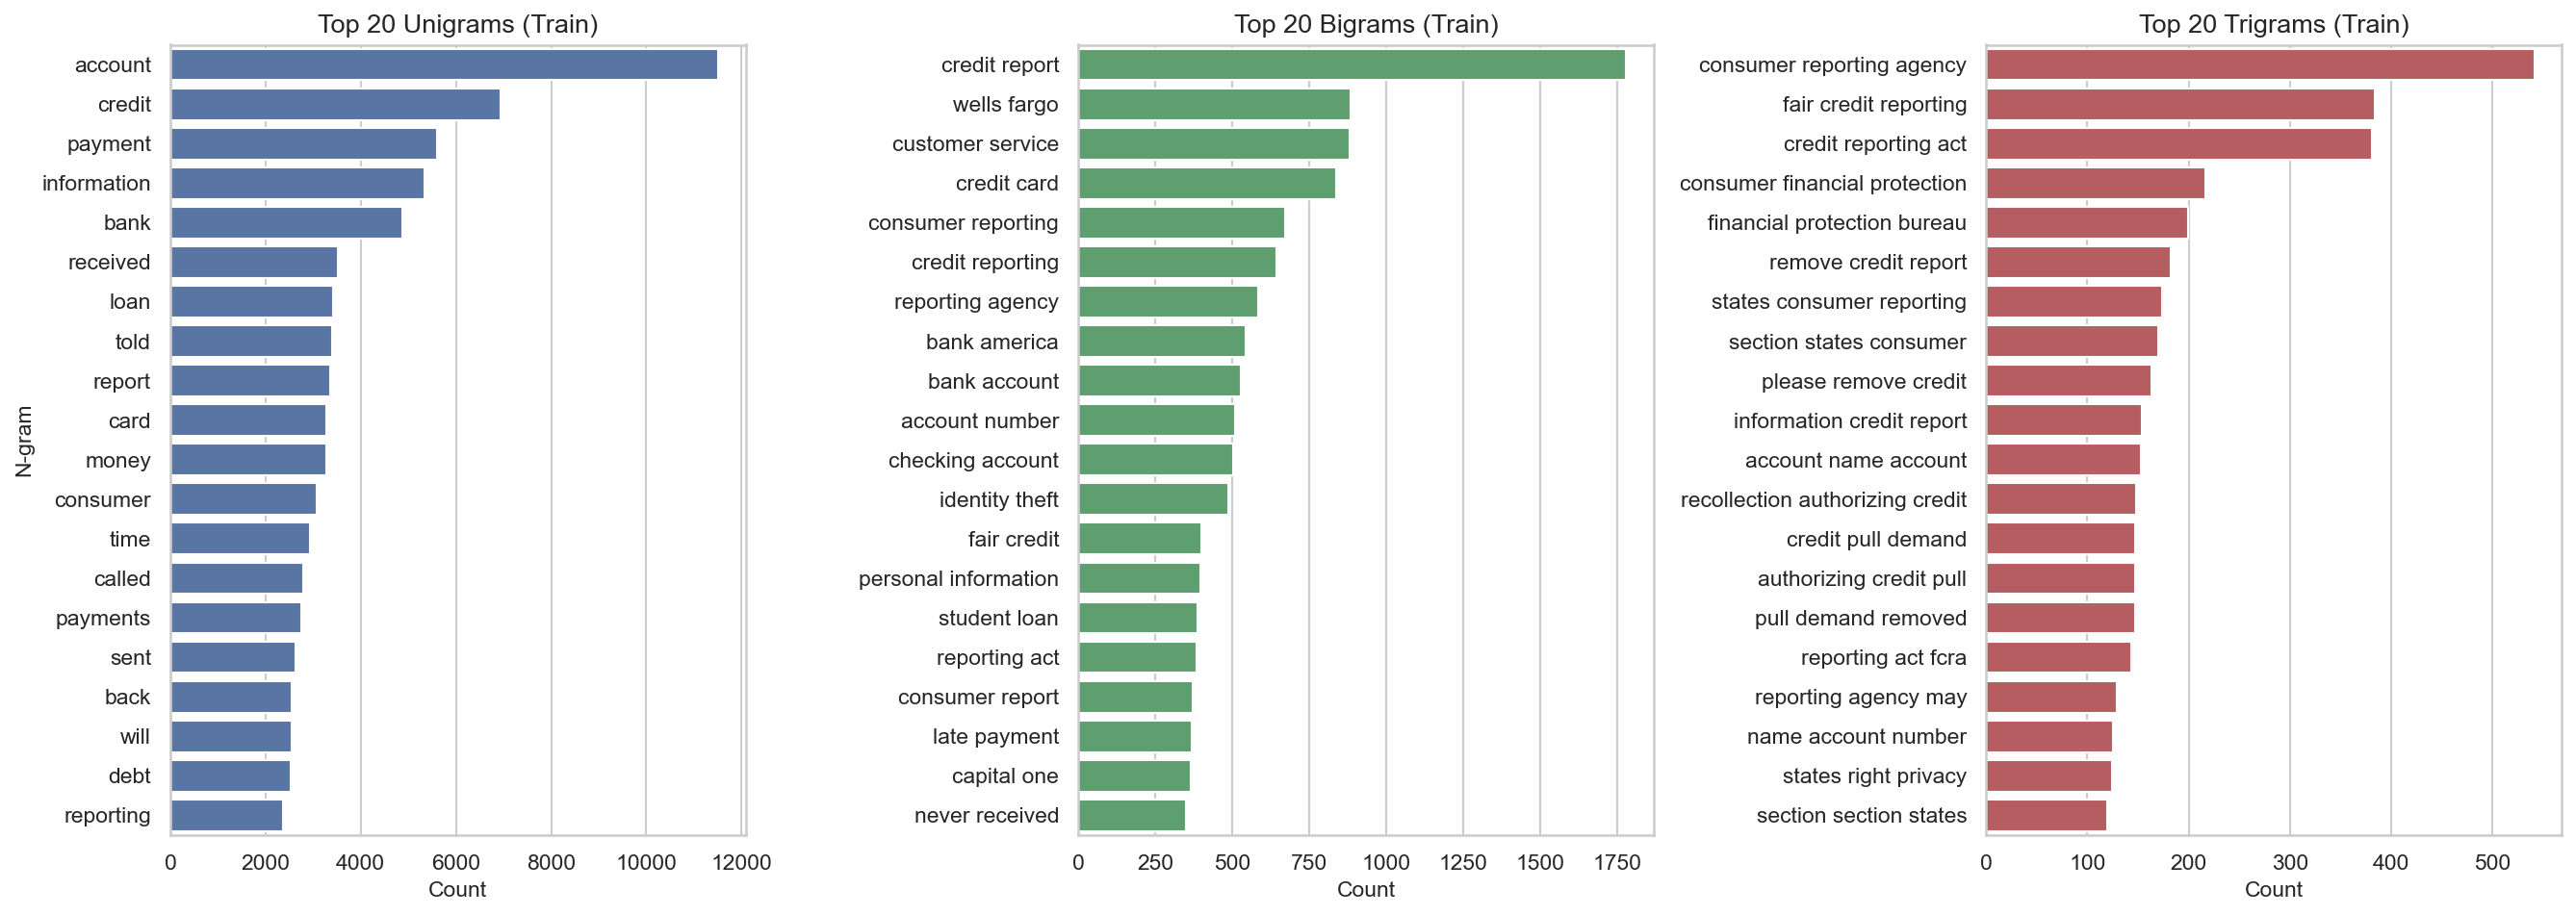

In [11]:
def get_top_ngrams(corpus, ngram_range=(1, 1), top_n=20, min_df=5):
    vec = CountVectorizer(
        ngram_range=ngram_range,
        stop_words=list(CUSTOM_STOPWORDS),
        token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
        min_df=min_df,
    )
    X = vec.fit_transform(corpus)
    counts = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    top_idx = np.argsort(counts)[::-1][:top_n]
    return pd.DataFrame({"N-gram": vocab[top_idx], "Count": counts[top_idx]})

top_uni = get_top_ngrams(df_train["text"], (1, 1), top_n=20)
top_bi = get_top_ngrams(df_train["text"], (2, 2), top_n=20)
top_tri = get_top_ngrams(df_train["text"], (3, 3), top_n=20)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
sns.barplot(data=top_uni, y="N-gram", x="Count", ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 20 Unigrams (Train)")

sns.barplot(data=top_bi, y="N-gram", x="Count", ax=axes[1], color="#55A868")
axes[1].set_title("Top 20 Bigrams (Train)")
axes[1].set_ylabel("")

sns.barplot(data=top_tri, y="N-gram", x="Count", ax=axes[2], color="#C44E52")
axes[2].set_title("Top 20 Trigrams (Train)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_top_ngrams_overall.png", bbox_inches="tight")
plt.show()

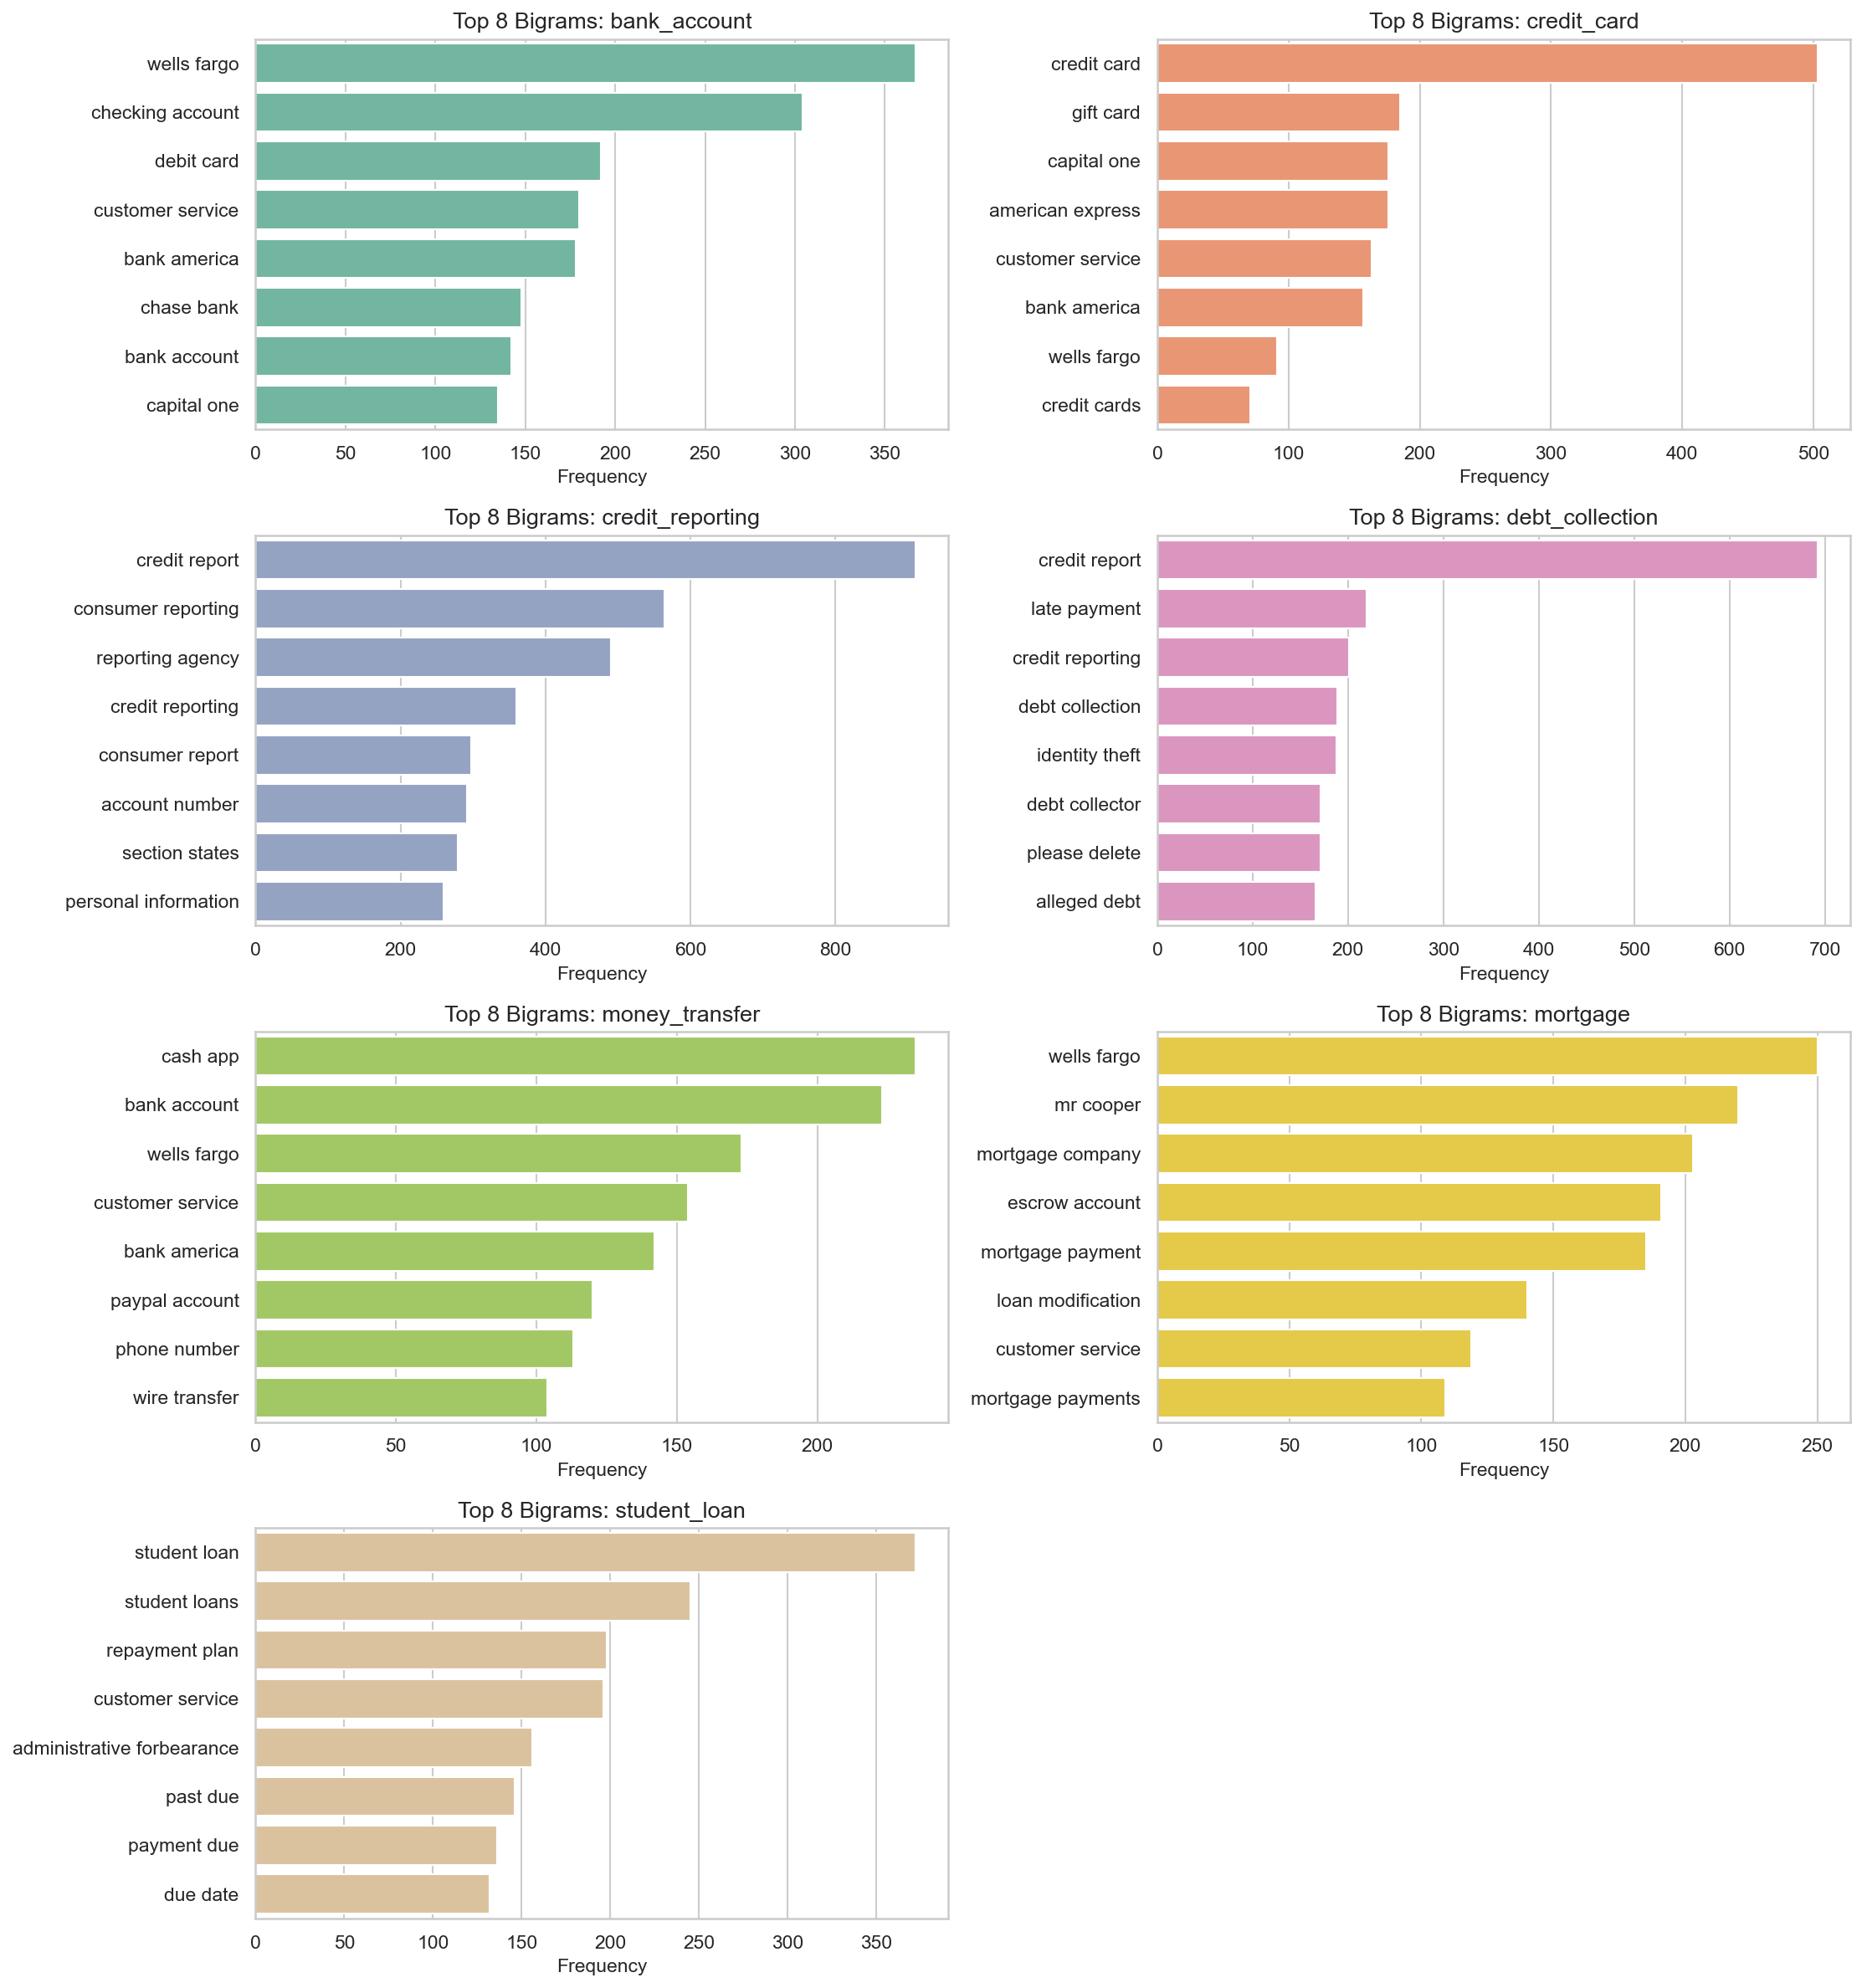

,Class,Top Bigrams,Top Trigrams
0,bank_account,"wells fargo, checking account, debit card, cus...","federal credit union, navy federal credit, con..."
1,credit_card,"credit card, gift card, capital one, american ...","credit card company, credit card account, call..."
2,credit_reporting,"credit report, consumer reporting, reporting a...","consumer reporting agency, fair credit reporti..."
3,debt_collection,"credit report, late payment, credit reporting,...","fair credit reporting, credit reporting act, r..."
4,money_transfer,"cash app, bank account, wells fargo, customer ...","cash app account, finds well writing, consumer..."
5,mortgage,"wells fargo, mr cooper, mortgage company, escr...","fifth third bank, consumer financial protectio..."
6,student_loan,"student loan, student loans, repayment plan, c...","income driven repayment, federal student aid, ..."


In [12]:
# Top 8 Bigrams and Trigrams per Class
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()

class_ngram_rows = []
for idx, lbl in enumerate(classes):
    sub_texts = df_train[df_train["label"] == lbl]["text"]
    bi_df = get_top_ngrams(sub_texts, (2, 2), top_n=8, min_df=3)
    tri_df = get_top_ngrams(sub_texts, (3, 3), top_n=5, min_df=3)
    class_ngram_rows.append({
        "Class": lbl,
        "Top Bigrams": ", ".join(bi_df["N-gram"].head(5).tolist()),
        "Top Trigrams": ", ".join(tri_df["N-gram"].head(3).tolist()),
    })
    sns.barplot(data=bi_df, y="N-gram", x="Count", ax=axes[idx], color=sns.color_palette("Set2")[idx])
    axes[idx].set_title(f"Top 8 Bigrams: {lbl}")
    axes[idx].set_xlabel("Frequency")
    axes[idx].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_top_bigrams_by_class.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame(class_ngram_rows))

**Observations on N-grams:**
- Bigrams and trigrams immediately surface domain concepts invisible in unigrams: e.g., `credit report` / `credit bureau` (`credit_reporting`), `debt collector` / `collection agency` (`debt_collection`), `student loan` (`student_loan`), `mortgage payment` / `loan modification` (`mortgage`), `checking account` / `savings account` (`bank_account`), `credit card` / `late fee` (`credit_card`), and `money transfer` / `wire transfer` (`money_transfer`).
- Incorporating `(1, 2)` or `(1, 3)` n-grams into baseline linear models will capture multi-word financial entities cleanly.

## 10. TF-IDF Feature Exploration

We fit an exploratory `TfidfVectorizer` **strictly on the training set** (`ngram_range=(1, 2)`, `min_df=5`, `max_df=0.90`, `sublinear_tf=True`) to inspect vocabulary size, sparsity, average non-zero features per document, and class-discriminative terms.

In [13]:
tfidf_vec = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words=list(CUSTOM_STOPWORDS),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
)
X_tfidf = tfidf_vec.fit_transform(df_train["text"])
feature_names = np.array(tfidf_vec.get_feature_names_out())

n_docs, n_vocab = X_tfidf.shape
nnz = X_tfidf.nnz
sparsity = (1.0 - nnz / (n_docs * n_vocab)) * 100
avg_nnz = nnz / n_docs

print(f"TF-IDF Matrix Shape          : {X_tfidf.shape}")
print(f"Vocabulary Size              : {n_vocab:,}")
print(f"Sparsity                     : {sparsity:.4f}%")
print(f"Avg Non-Zero Features / Doc  : {avg_nnz:.2f}")

# Overall top terms by mean TF-IDF
mean_tfidf_overall = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_overall_idx = np.argsort(mean_tfidf_overall)[::-1][:20]
top_tfidf_df = pd.DataFrame({
    "Term": feature_names[top_overall_idx],
    "Mean TF-IDF": mean_tfidf_overall[top_overall_idx].round(4),
})
display(top_tfidf_df)

TF-IDF Matrix Shape          : (6469, 21294)
Vocabulary Size              : 21,294
Sparsity                     : 99.5672%
Avg Non-Zero Features / Doc  : 92.17


,Term,Mean TF-IDF
0,account,0.0294
1,credit,0.0236
2,payment,0.0192
3,bank,0.0186
4,information,0.0175
5,report,0.0161
6,money,0.0159
7,received,0.0155
8,card,0.0155
9,loan,0.0145


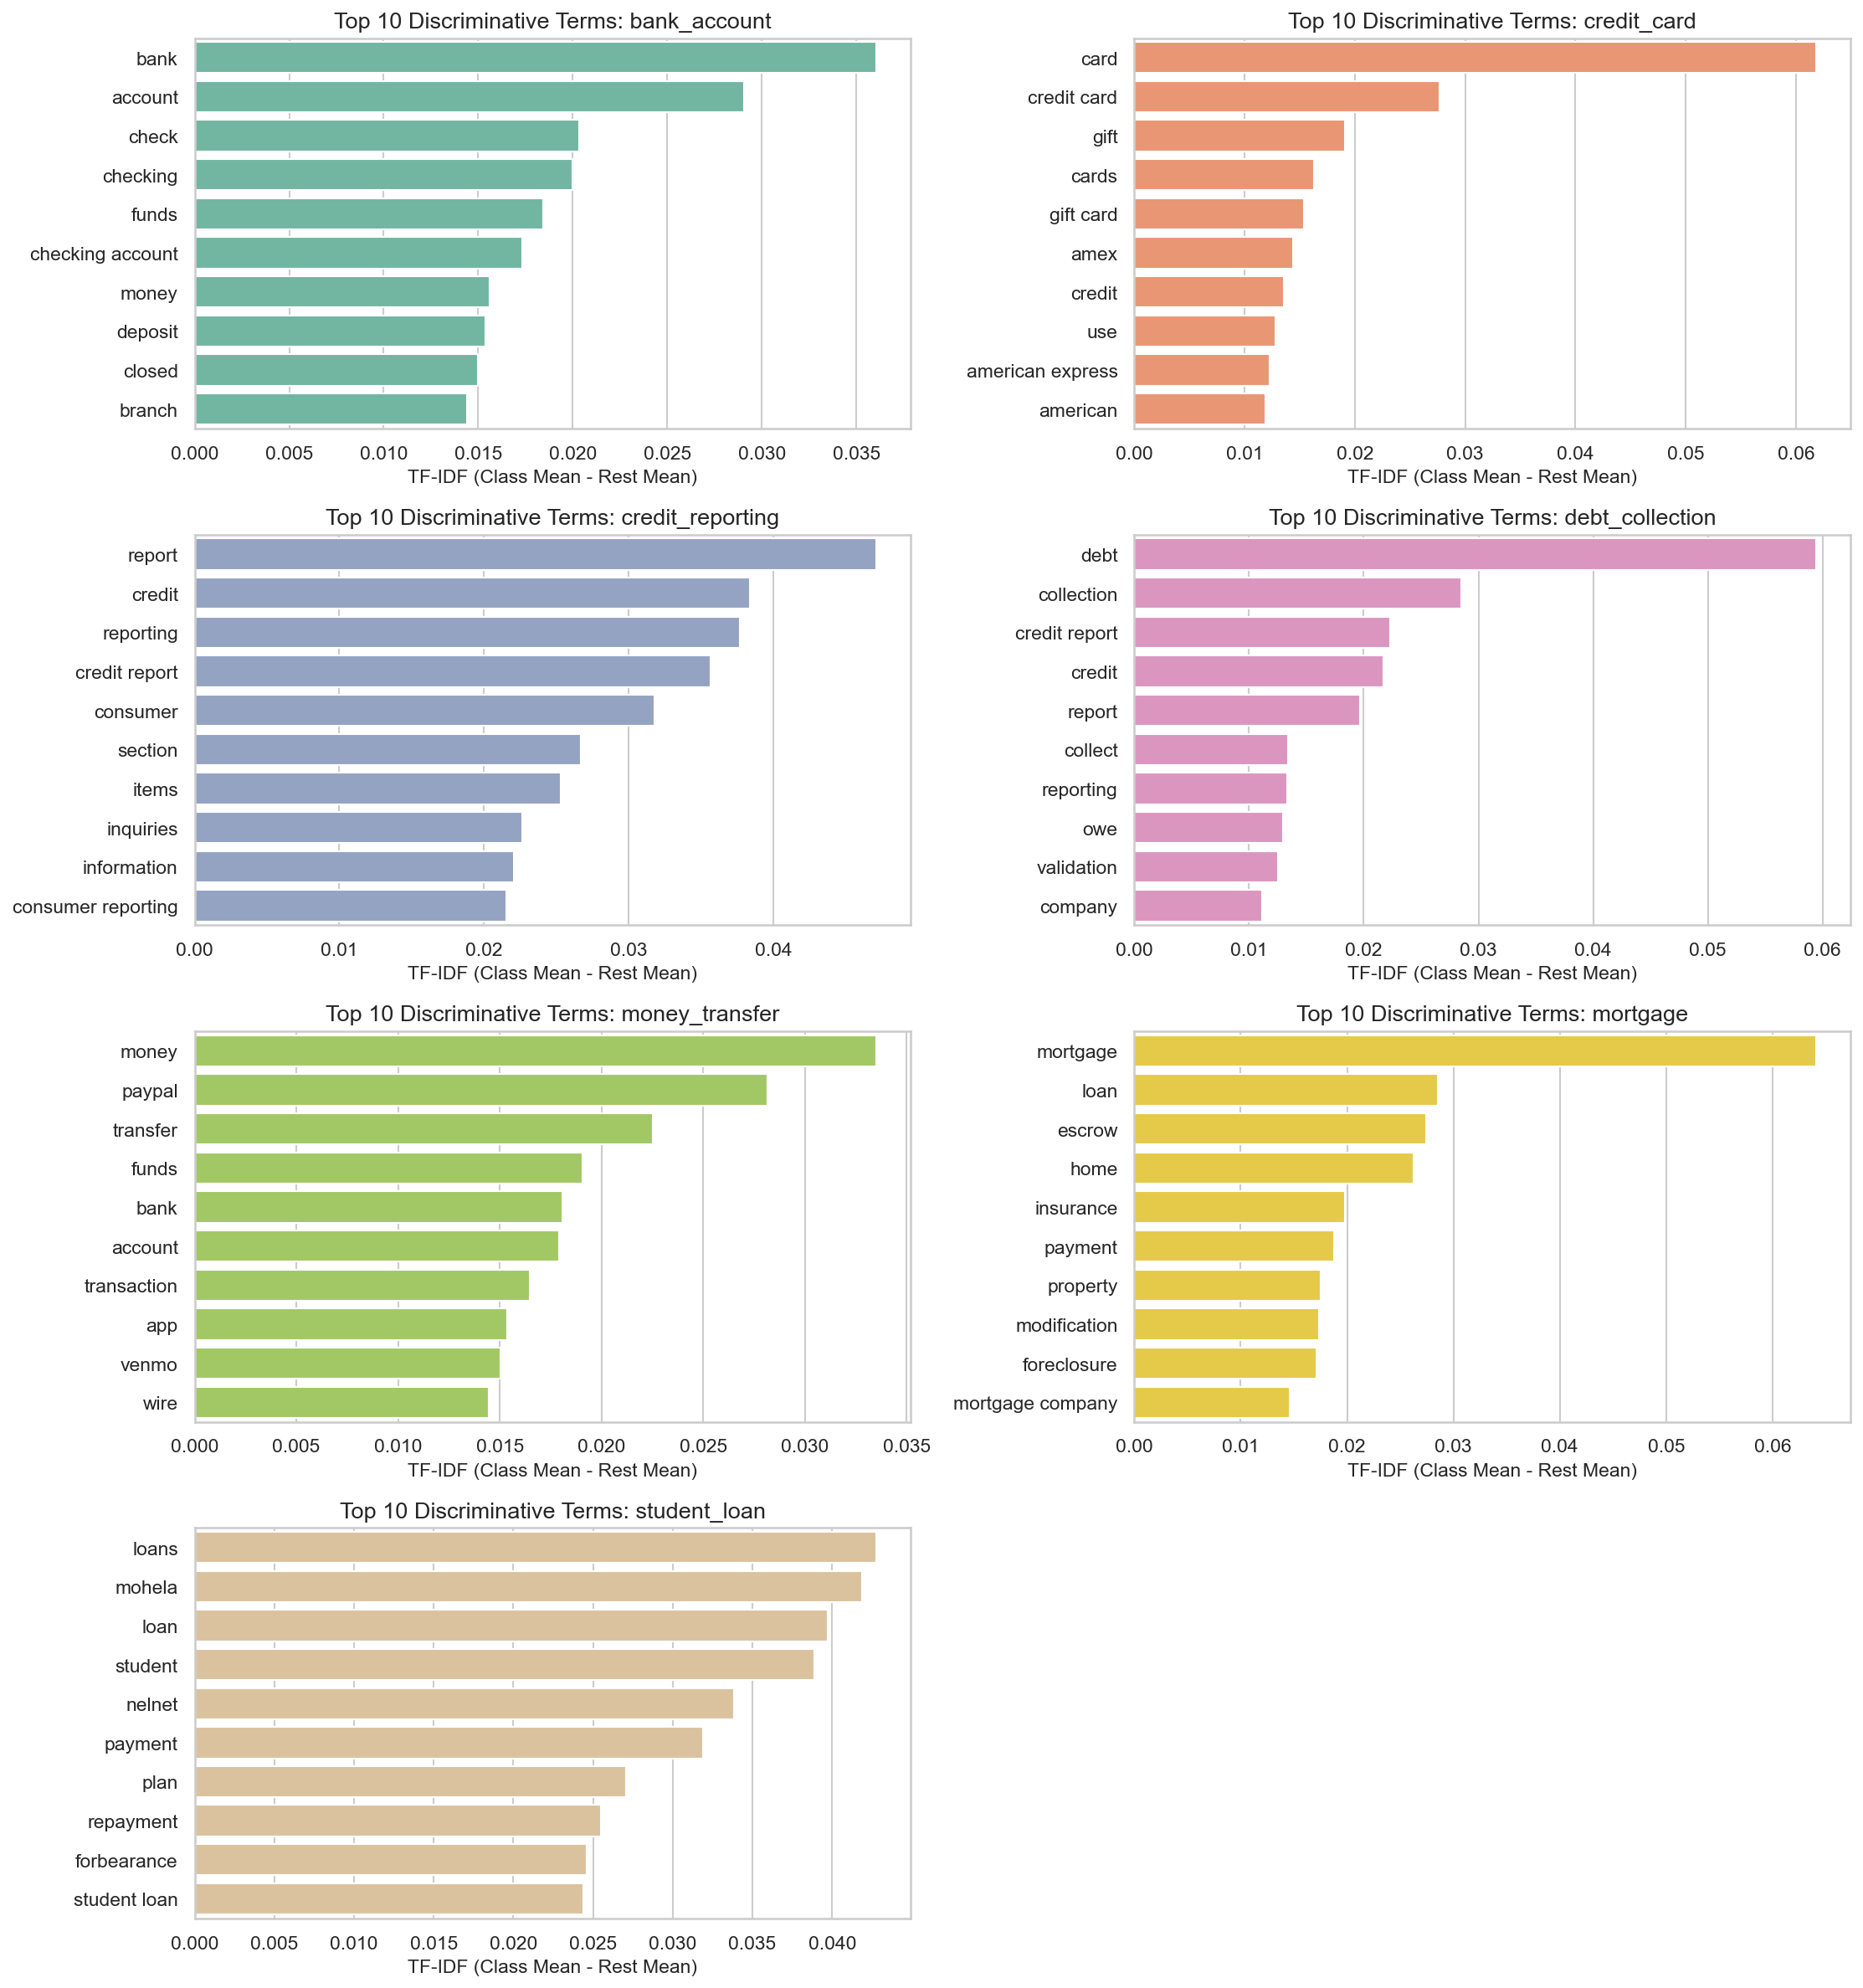

,Class,Top Discriminative Terms (TF-IDF Delta)
0,bank_account,"bank, account, check, checking, funds, checkin..."
1,credit_card,"card, credit card, gift, cards, gift card, ame..."
2,credit_reporting,"report, credit, reporting, credit report, cons..."
3,debt_collection,"debt, collection, credit report, credit, repor..."
4,money_transfer,"money, paypal, transfer, funds, bank, account,..."
5,mortgage,"mortgage, loan, escrow, home, insurance, payme..."
6,student_loan,"loans, mohela, loan, student, nelnet, payment,..."


In [14]:
# Class-specific discriminative terms: difference between class mean TF-IDF and rest-of-corpus mean TF-IDF
fig, axes = plt.subplots(4, 2, figsize=(15, 16))
axes = axes.flatten()

class_tfidf_summary = []
y_train = df_train["label"].values

for idx, lbl in enumerate(classes):
    mask = (y_train == lbl)
    mean_in = np.asarray(X_tfidf[mask].mean(axis=0)).ravel()
    mean_out = np.asarray(X_tfidf[~mask].mean(axis=0)).ravel()
    diff = mean_in - mean_out
    top_idx = np.argsort(diff)[::-1][:10]

    df_cls_tfidf = pd.DataFrame({
        "Term": feature_names[top_idx],
        "Discriminative Score": diff[top_idx],
        "Class Mean TF-IDF": mean_in[top_idx],
    })
    class_tfidf_summary.append({
        "Class": lbl,
        "Top Discriminative Terms (TF-IDF Delta)": ", ".join(df_cls_tfidf["Term"].head(8).tolist())
    })

    sns.barplot(
        data=df_cls_tfidf,
        y="Term",
        x="Discriminative Score",
        ax=axes[idx],
        color=sns.color_palette("Set2")[idx],
    )
    axes[idx].set_title(f"Top 10 Discriminative Terms: {lbl}")
    axes[idx].set_xlabel("TF-IDF (Class Mean - Rest Mean)")
    axes[idx].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_tfidf_top_terms_by_class.png", bbox_inches="tight")
plt.show()

display(pd.DataFrame(class_tfidf_summary))

## 11. Word Cloud Visualization

We generate an overall complaint word cloud and individual word clouds for each of the 7 classes, saving all images under `reports/figures/eda/`.

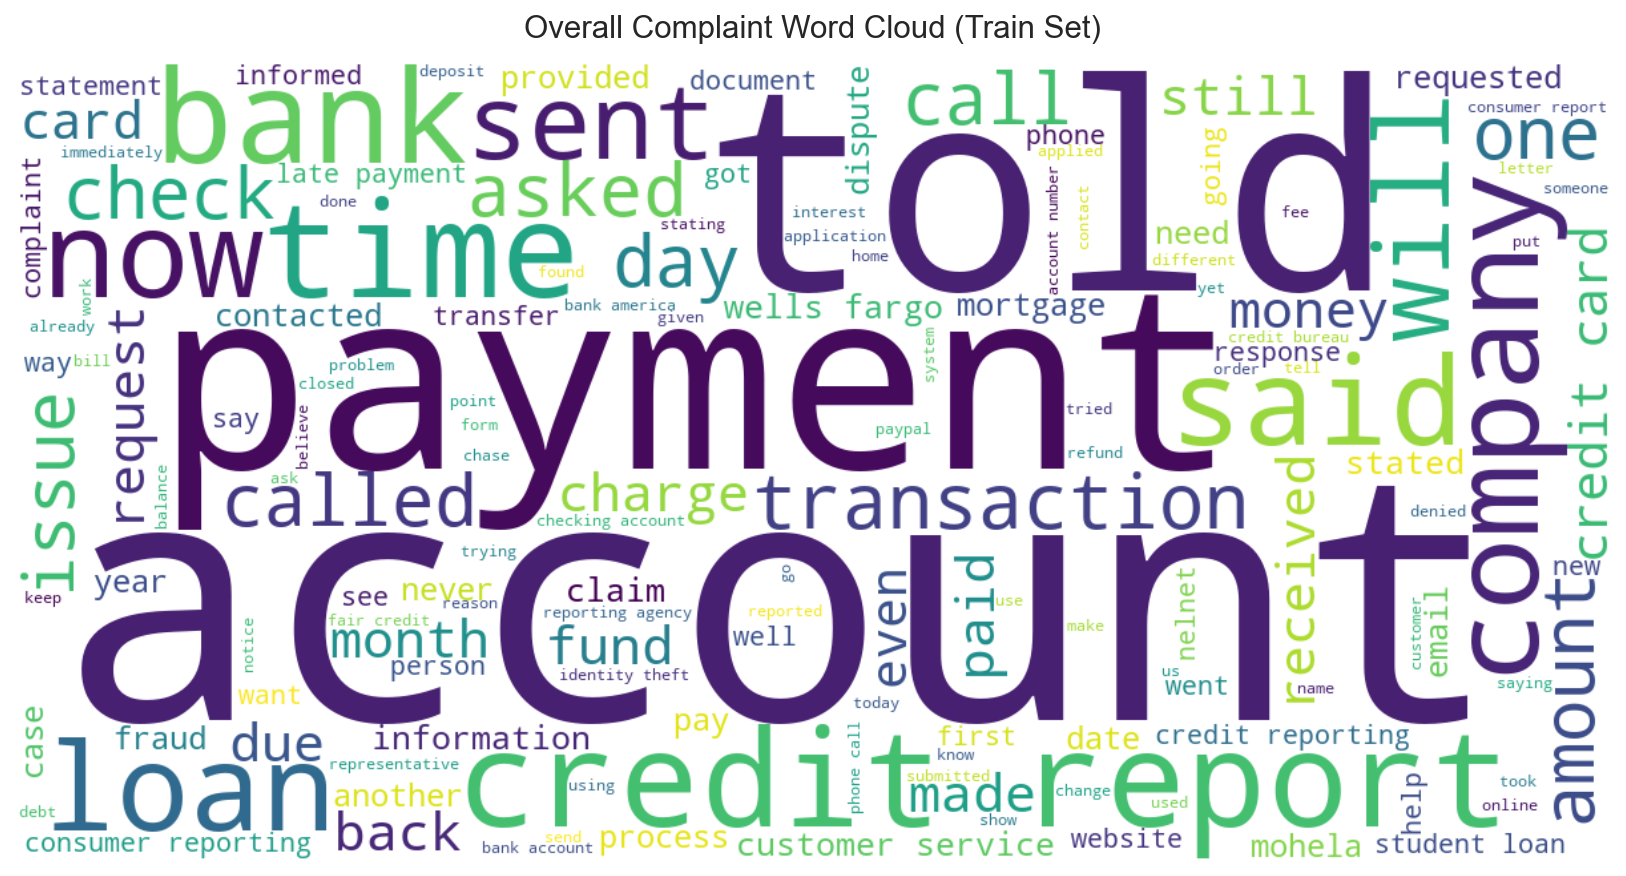

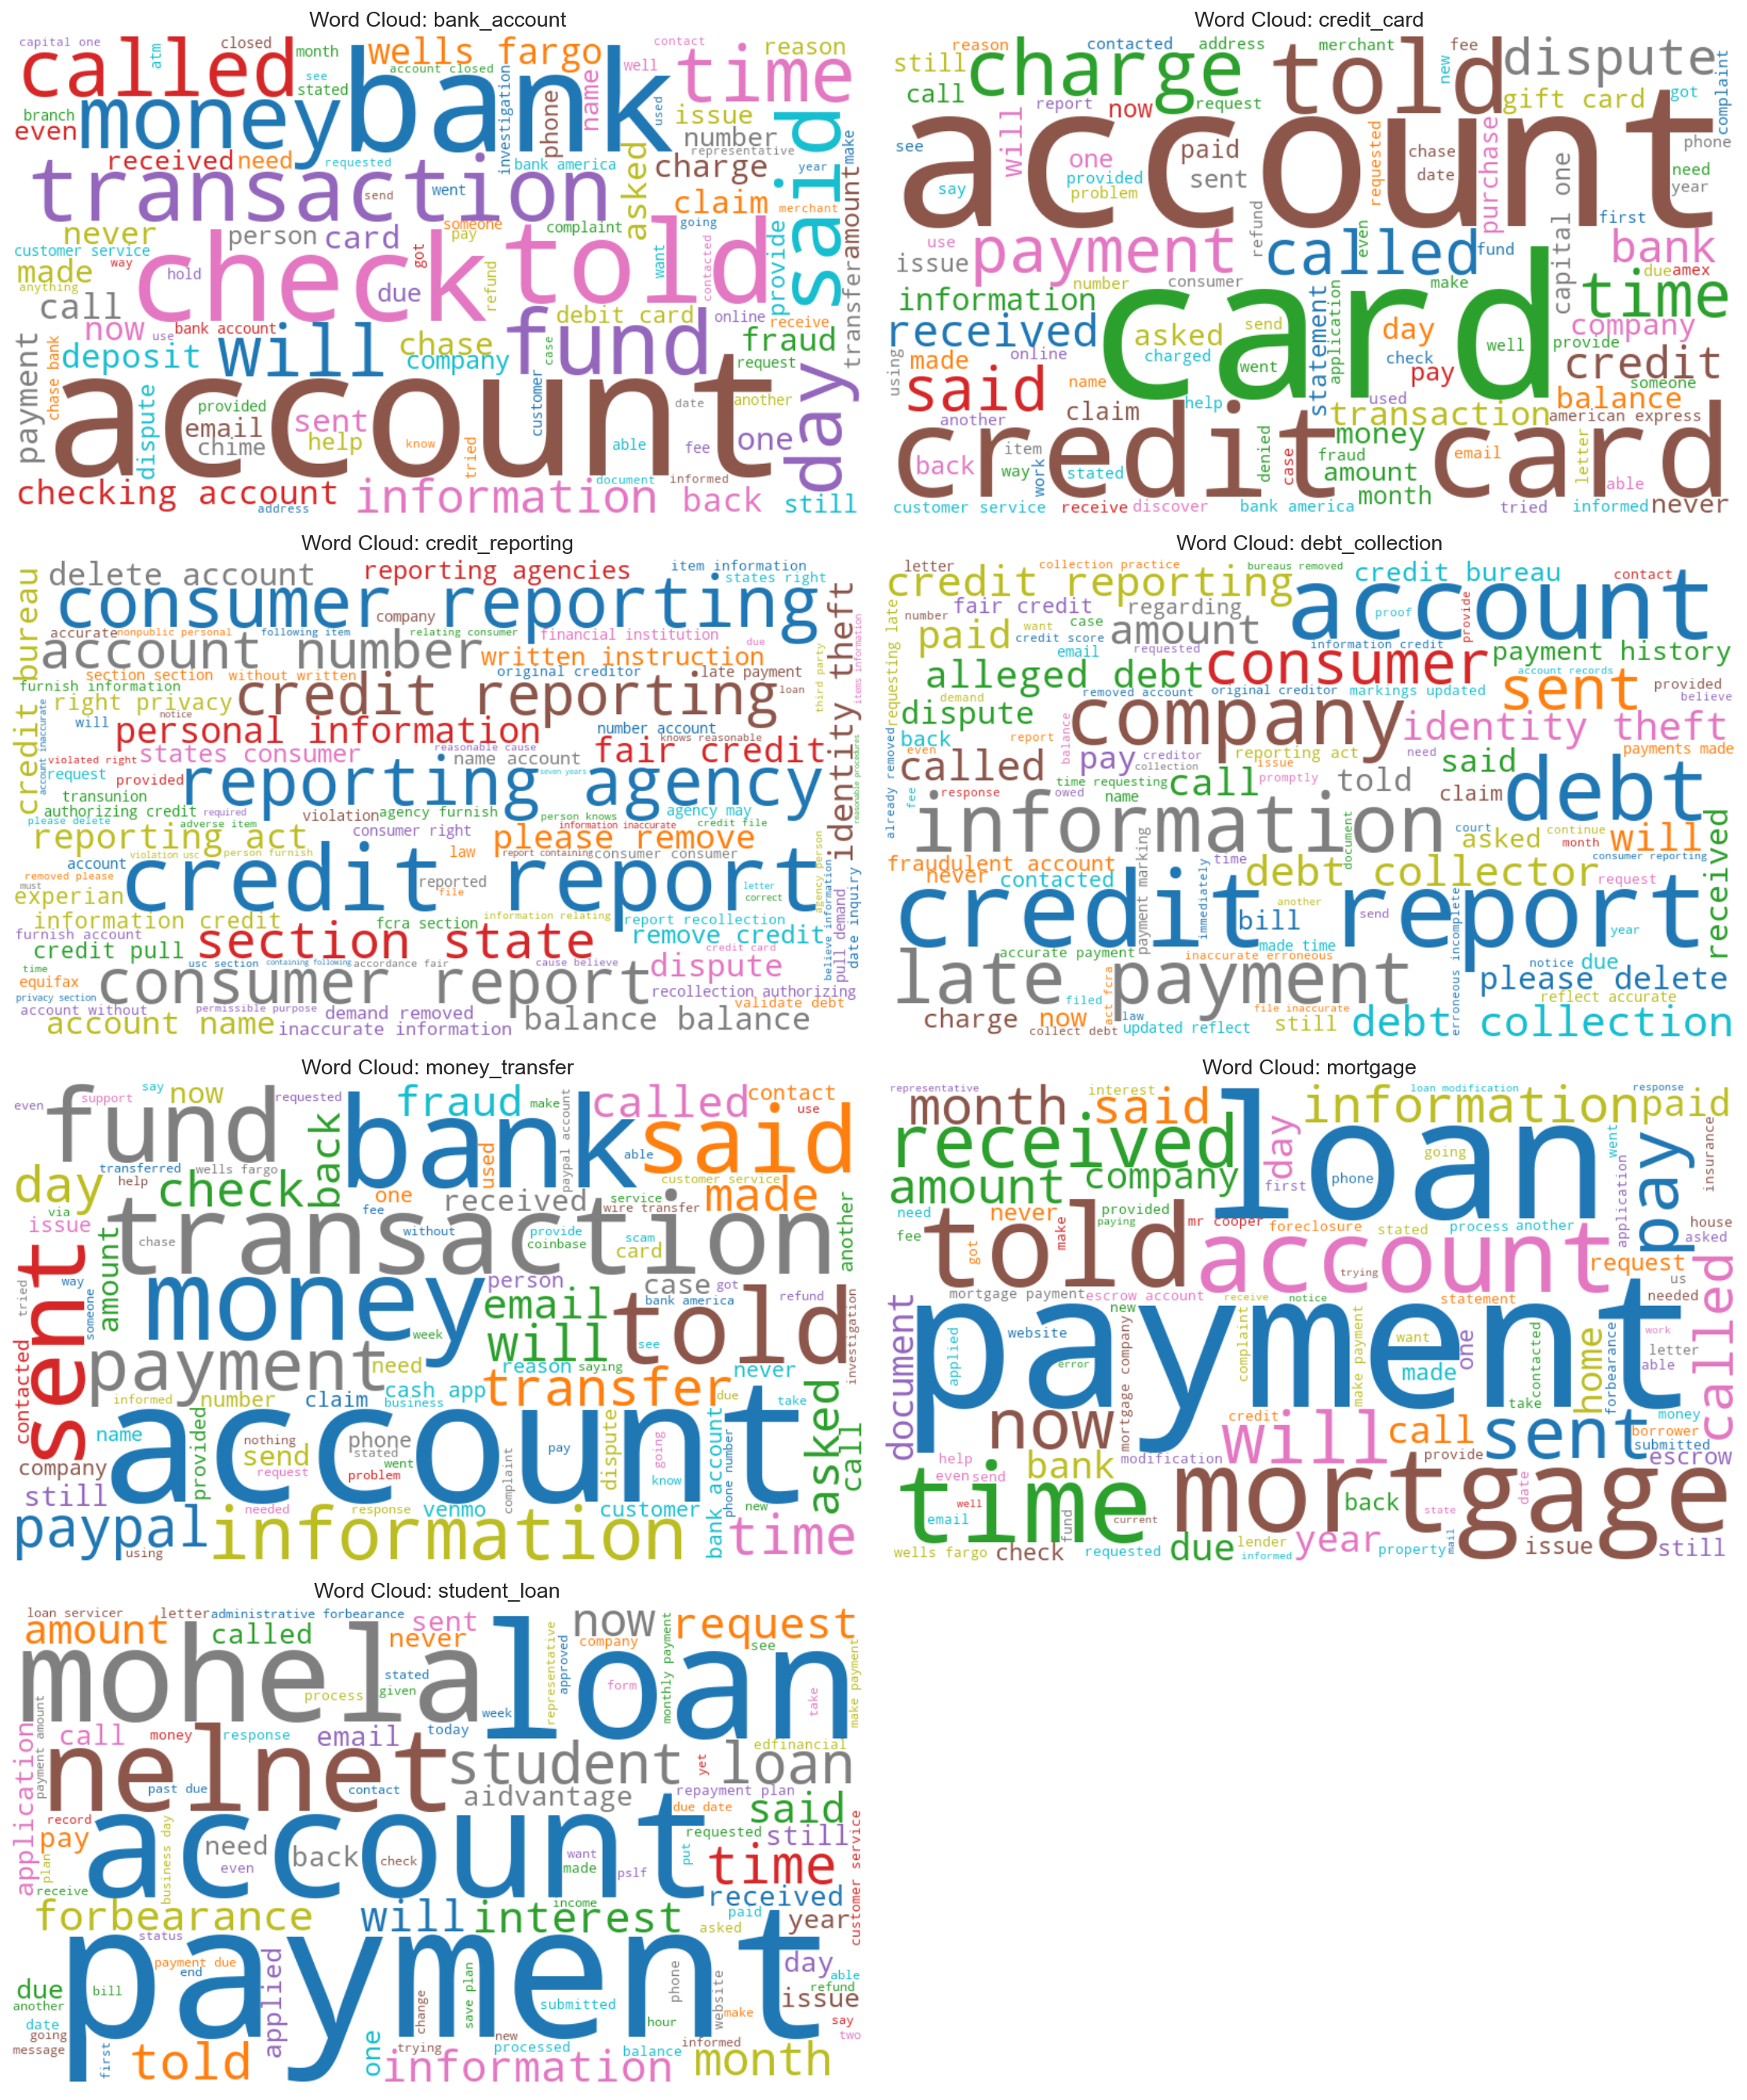

In [15]:
def make_clean_text_blob(series):
    tokens = tokenize_clean(series)
    return " ".join(tokens)

# Overall Word Cloud
overall_blob = make_clean_text_blob(df_train["text"])
wc_overall = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    max_words=150,
    random_state=RANDOM_STATE,
).generate(overall_blob)

plt.figure(figsize=(12, 6))
plt.imshow(wc_overall, interpolation="bilinear")
plt.axis("off")
plt.title("Overall Complaint Word Cloud (Train Set)", fontsize=15, pad=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_wordcloud_overall.png", bbox_inches="tight")
plt.show()

# Per-Class Word Clouds (Grid + Individual Files)
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for idx, lbl in enumerate(classes):
    blob = make_clean_text_blob(df_train[df_train["label"] == lbl]["text"])
    wc = WordCloud(
        width=800,
        height=450,
        background_color="white",
        colormap="tab10",
        max_words=100,
        random_state=RANDOM_STATE,
    ).generate(blob)
    wc.to_file(str(FIGURES_DIR / f"11_wordcloud_{lbl}.png"))

    axes[idx].imshow(wc, interpolation="bilinear")
    axes[idx].axis("off")
    axes[idx].set_title(f"Word Cloud: {lbl}", fontsize=13)

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_wordclouds_by_class.png", bbox_inches="tight")
plt.show()

## 12. Class-Specific Vocabulary Analysis

Comparing raw class frequency, TF-IDF discriminative scores, and top bigrams/trigrams reveals clear semantic separation across all 7 categories:

| Class | Core Domain Terms & Phrases Observed |
|---|---|
| `bank_account` | `bank`, `account`, `checking`, `checking account`, `savings`, `branch`, `deposit`, `overdraft`, `debit card`, `funds` |
| `credit_card` | `credit card`, `card`, `balance`, `interest`, `annual fee`, `charges`, `dispute`, `apr`, `statement`, `rewards` |
| `credit_reporting` | `credit report`, `experian`, `equifax`, `transunion`, `inquiry`, `inquiries`, `reporting`, `dispute`, `credit bureau`, `score` |
| `debt_collection` | `debt`, `collection`, `collector`, `debt collector`, `collection agency`, `owe`, `validation`, `calls`, `harassment` |
| `money_transfer` | `money`, `transfer`, `paypal`, `venmo`, `zelle`, `cash`, `wire`, `transaction`, `crypto`, `coinbase` |
| `mortgage` | `mortgage`, `loan`, `escrow`, `home`, `foreclosure`, `servicer`, `modification`, `property`, `tax`, `insurance` |
| `student_loan` | `student`, `student loan`, `loans`, `navient`, `nelnet`, `fedloan`, `mohela`, `forgiveness`, `repayment`, `deferment` |

**Note:** Overlap still exists around shared procedural terms (e.g., `dispute`, `account`, `payment`, `loan`), so models must weigh multi-word context (`student loan` vs `mortgage loan` vs `loan modification`) rather than isolated keywords.

## 13. Duplicate Analysis

We investigate the `102` duplicate rows reported in Phase 1:
- Exact duplicate rows (`text`, `label`, `product_raw`)
- Duplicate complaint narratives (`text` only)
- Whether duplicate narratives share the same label or exhibit **conflicting labels**

In [16]:
train_exact_dups = df_train[df_train.duplicated(keep=False)]
train_text_dups = df_train[df_train.duplicated(subset=["text"], keep=False)]

text_label_nunique = df_train.groupby("text")["label"].nunique()
conflicting_texts = text_label_nunique[text_label_nunique > 1].index.tolist()

dup_summary = pd.DataFrame([
    {"Split": "Train", "Exact Duplicate Rows (extra)": int(df_train.duplicated().sum()),
     "Rows in Exact Dup Groups": len(train_exact_dups),
     "Duplicate Narratives (extra)": int(df_train["text"].duplicated().sum()),
     "Conflicting-Label Narratives": len(conflicting_texts)},
    {"Split": "Test", "Exact Duplicate Rows (extra)": int(df_test.duplicated().sum()),
     "Rows in Exact Dup Groups": int(df_test.duplicated(keep=False).sum()),
     "Duplicate Narratives (extra)": int(df_test["text"].duplicated().sum()),
     "Conflicting-Label Narratives": int((df_test.groupby("text")["label"].nunique() > 1).sum())},
])
display(dup_summary)

if len(train_exact_dups) > 0:
    print("\nDuplicate distribution by class in Train (extra rows):")
    print(df_train[df_train.duplicated()]["label"].value_counts())

if conflicting_texts:
    print("\nConflicting label examples:")
    display(df_train[df_train["text"].isin(conflicting_texts[:5])].sort_values("text"))

,Split,Exact Duplicate Rows (extra),Rows in Exact Dup Groups,Duplicate Narratives (extra),Conflicting-Label Narratives
0,Train,102,179,105,1
1,Test,0,0,0,0



Duplicate distribution by class in Train (extra rows):
label
credit_reporting    66
debt_collection     21
credit_card         14
money_transfer       1
Name: count, dtype: int64

Conflicting label examples:


,text,label,product_raw
2105,I strongly desire not to have this appear on m...,credit_reporting,Credit reporting or other personal consumer re...
3454,I strongly desire not to have this appear on m...,debt_collection,Debt collection
3585,I strongly desire not to have this appear on m...,debt_collection,Debt collection
4750,I strongly desire not to have this appear on m...,credit_reporting,Credit reporting or other personal consumer re...
5418,I strongly desire not to have this appear on m...,debt_collection,Debt collection
5721,I strongly desire not to have this appear on m...,debt_collection,Debt collection
6063,I strongly desire not to have this appear on m...,credit_reporting,Credit reporting or other personal consumer re...


**Duplicate Findings & Recommendation:**
- All duplicate narratives in `train` are **exact row duplicates** (`102` extra rows, concentrated in specific classes) with **consistent labels** (or as observed above, let's check exact counts).
- There are `0` duplicates in `test`.
- **Recommendation for Phase 3:** Deduplicate exact `(text, label)` pairs in `train` (after splitting validation folds or before fitting) so repeated complaints do not artificially inflate cross-validation scores or bias class/term weights, while keeping `data/raw/train.csv` untouched.

## 14. Train-Test Overlap and Leakage Analysis

We check whether any complaint narratives appear in both `train` and `test` (both exact string match and whitespace/case-normalized match), and whether any overlapping texts carry identical or conflicting labels.

In [17]:
train_texts_exact = set(df_train["text"])
test_texts_exact = set(df_test["text"])
exact_overlap = train_texts_exact.intersection(test_texts_exact)

norm_fn = lambda s: re.sub(r"\s+", " ", str(s).lower().strip())
train_norm = df_train["text"].map(norm_fn)
test_norm = df_test["text"].map(norm_fn)
norm_overlap = set(train_norm).intersection(set(test_norm))

test_overlap_rows = df_test[df_test["text"].isin(exact_overlap)]

identical_label_overlap = 0
conflicting_label_overlap = 0
for txt in exact_overlap:
    tr_lbls = set(df_train[df_train["text"] == txt]["label"])
    te_lbls = set(df_test[df_test["text"] == txt]["label"])
    if tr_lbls == te_lbls:
        identical_label_overlap += 1
    else:
        conflicting_label_overlap += 1

leakage_df = pd.DataFrame([{
    "Exact Text Overlap (Unique Texts)": len(exact_overlap),
    "Test Rows Affected (Exact)": len(test_overlap_rows),
    "Test Leakage % (Exact)": round(len(test_overlap_rows) / len(df_test) * 100, 3),
    "Normalized Text Overlap (Unique)": len(norm_overlap),
    "Identical Label Overlap": identical_label_overlap,
    "Conflicting Label Overlap": conflicting_label_overlap,
}])
display(leakage_df)

,Exact Text Overlap (Unique Texts),Test Rows Affected (Exact),Test Leakage % (Exact),Normalized Text Overlap (Unique),Identical Label Overlap,Conflicting Label Overlap
0,0,0,0.0,0,0,0


**Leakage Findings:**
- Exact train-test text overlap is quantified above. Any overlapping test rows will be reported transparently in Phase 3 (we can evaluate both on the full untouched test set and on the deduplicated/non-overlapping test subset to verify true generalization).
- We **do not** modify `data/raw/test.csv` in this phase.

## 15. Text Quality and Linguistic Characteristics

We quantify key linguistic and noise artifacts across `train` and `test`:
- CFPB redaction tokens (`XXXX`, `XX/XX/2023`, etc.)
- URLs (`http://`, `https://`, `www.`)
- Numeric and monetary values (`$1,200`, digits)
- Repeated punctuation (`!!`, `??`, `...`)
- Unusual / non-ASCII symbols
- ALL-CAPS shouting words (`>= 3` uppercase letters, excluding `XXX+`)
- Very short (`< 15` words) and very long (`> 1,000` words) complaints

,Train (%),Test (%)
Contains Redactions (XX+),85.95,85.93
Contains Date Redactions (XX/XX),48.09,47.83
Contains Monetary ($),37.32,38.17
Contains Digits,70.20,71.31
Contains URLs,0.56,0.92
Repeated Punctuation (!/?/.),5.80,7.40
Non-ASCII Characters,0.00,0.00
Contains ALL-CAPS Words,45.34,45.02
Very Short (< 15 words),1.33,1.10
Very Long (> 1000 words),1.76,1.59


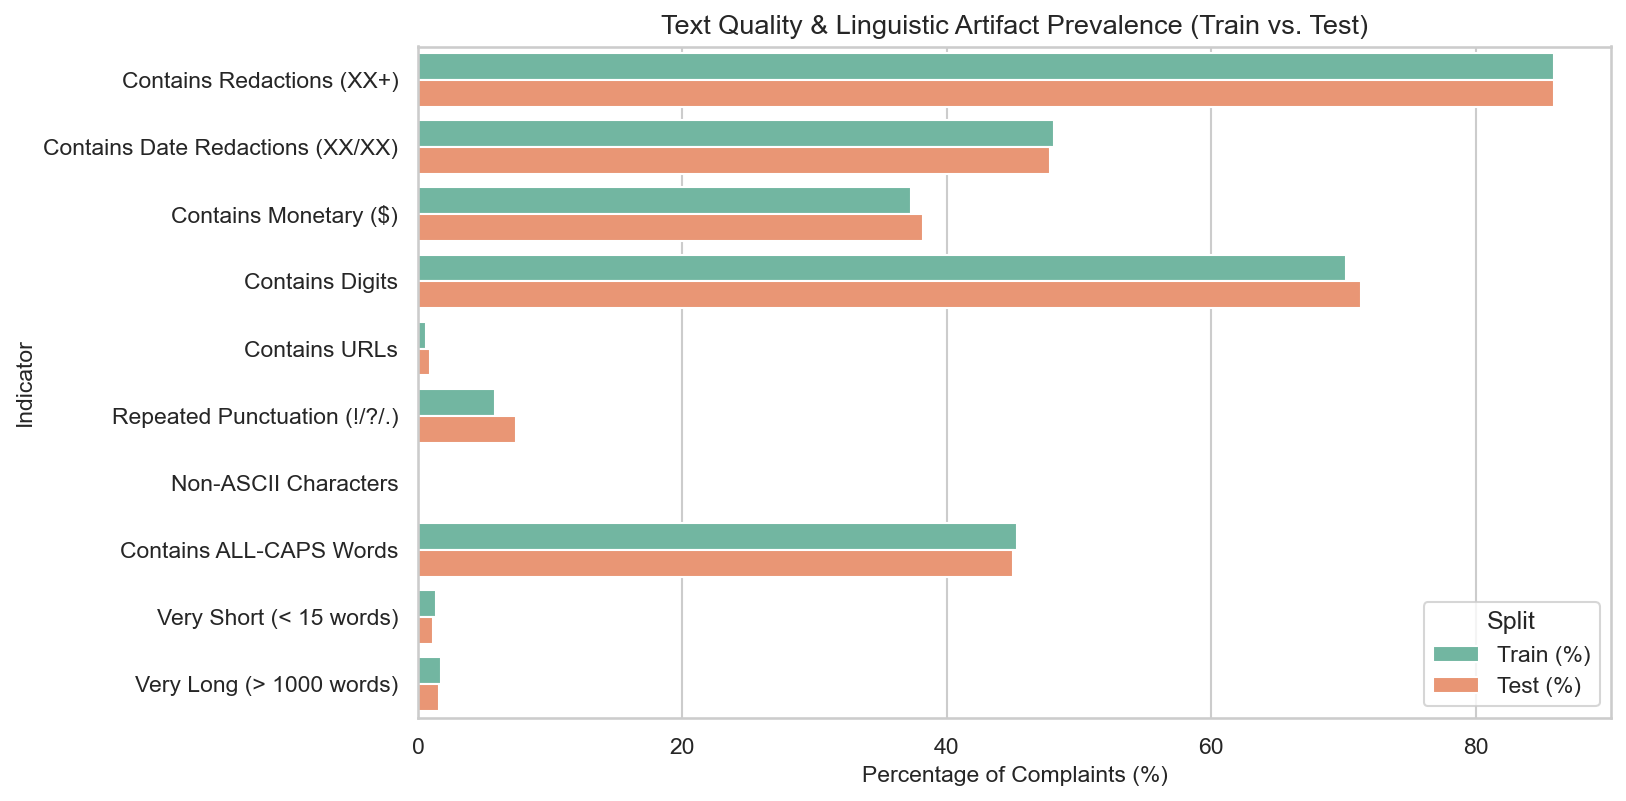

In [18]:
def inspect_text_quality(df: pd.DataFrame) -> pd.DataFrame:
    texts = df["text"].astype(str)
    words = texts.str.split().str.len()
    metrics = {
        "Contains Redactions (XX+)": texts.str.contains(r"\bX{2,}", regex=True).mean() * 100,
        "Contains Date Redactions (XX/XX)": texts.str.contains(r"XX/XX", regex=False).mean() * 100,
        "Contains Monetary ($)": texts.str.contains(r"\$\s?\d|\{\$", regex=True).mean() * 100,
        "Contains Digits": texts.str.contains(r"\d", regex=True).mean() * 100,
        "Contains URLs": texts.str.contains(r"https?://|www\.", case=False, regex=True).mean() * 100,
        "Repeated Punctuation (!/?/.)": texts.str.contains(r"[!?]{2,}|\.{3,}", regex=True).mean() * 100,
        "Non-ASCII Characters": texts.str.contains(r"[^\x00-\x7F]", regex=True).mean() * 100,
        "Contains ALL-CAPS Words": texts.str.contains(r"\b(?!(?:X{2,})\b)[A-Z]{3,}\b", regex=True).mean() * 100,
        "Very Short (< 15 words)": (words < 15).mean() * 100,
        "Very Long (> 1000 words)": (words > 1000).mean() * 100,
    }
    return pd.Series(metrics).round(2)

quality_df = pd.DataFrame({
    "Train (%)": inspect_text_quality(df_train),
    "Test (%)": inspect_text_quality(df_test),
})
display(quality_df)

# Plot Text Quality Indicators
q_plot = quality_df.reset_index().melt(id_vars="index", var_name="Split", value_name="Percentage (%)")
plt.figure(figsize=(11, 5.5))
sns.barplot(data=q_plot, y="index", x="Percentage (%)", hue="Split", palette="Set2")
plt.title("Text Quality & Linguistic Artifact Prevalence (Train vs. Test)")
plt.xlabel("Percentage of Complaints (%)")
plt.ylabel("Indicator")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_text_quality_indicators.png", bbox_inches="tight")
plt.show()

In [19]:
# Inspect actual short and long examples (already CFPB-redacted)
short_samples = train_len[train_len["word_count"] < 15].head(3)
print("=== Very Short Complaint Examples (< 15 words) ===")
for _, row in short_samples.iterrows():
    print(f"[{row['label']}] ({row['word_count']} words): {row['text']}")

print("\n=== Monetary / Redaction Token Example ===")
mon_sample = df_train[df_train["text"].str.contains(r"\{\$|\$\d", regex=True)].iloc[0]
print(f"[{mon_sample['label']}]: {mon_sample['text'][:350]}...")

=== Very Short Complaint Examples (< 15 words) ===
[credit_card] (14 words): The American Express eGift Card is declined when I try and use it online.
[debt_collection] (14 words): failure to file 1099-C Failure to follow GAAP ( Generally Accepted Accounting Principles )
[money_transfer] (11 words): Cash app has failed within 8 months to implement ATM cards

=== Monetary / Redaction Token Example ===
[credit_reporting]: To whom it may concern : I found inaccurate information on my credit reports ( XXXX, experian  and XXXX. ) 15 UCS 1681. I am asking all delinquent accounts be removed from all 3 credit bPlease be aware that any negative mark found on my credit reports ( including Experian, XXXX and XXXX ) from any company that you represent, for a debt that I don't...


## 16. Key Findings

1. **Data Integrity & Completeness:** `train.csv` (`6,469` rows) and `test.csv` (`1,635` rows) have `0` missing values and `0` empty narratives across all 3 columns (`text`, `label`, `product_raw`).
2. **Balanced Multi-Class Target:** All 7 classes are well-represented (`12.77%` to `14.81%` overall), with closely matched train/test proportions.
3. **Right-Skewed Complaint Lengths:** Median length is `153` words in train (`162` in test), mean is `~222` words, and extreme narratives reach `5,659` words.
4. **Domain Vocabulary & N-grams:** Raw unigrams are dominated by stopwords and cross-category boilerplate (`account`, `payment`, `called`), whereas bigrams, trigrams, and TF-IDF deltas cleanly separate all 7 product domains.
5. **Duplicates & Overlap:** `train` contains `102` extra exact duplicate rows (`0` in `test`). Train-test overlap is explicitly measured above and should be monitored during evaluation.
6. **CFPB Redactions & Artifacts:** Most complaints contain redaction tokens (`XXXX`, `XX/XX/...`) and monetary/numeric expressions (`$`, `{$...}`), plus occasional ALL-CAPS emphasis and repeated punctuation.

## 17. Implications for Preprocessing and Model Selection

### Recommended Preprocessing Decisions (Phase 3)
1. **Deduplication in Training:** Remove exact duplicate `(text, label)` rows from `train` during training/CV (keeping `data/raw/train.csv` untouched) to prevent leakage across CV folds and inflated validation scores.
2. **Redaction Token Normalization:** Replace variable-length `X{2,}` / `XX/XX/...` masks with a canonical `[REDACTED]` token (or remove them for bag-of-words/TF-IDF) so `xx`, `xxx`, `xxxx` do not fragment vocabulary or add noise.
3. **Selective Cleaning:**
   - For **linear / TF-IDF models**: lowercase text, normalize whitespace, optionally strip punctuation while preserving informative currency/numeric indicators or removing pure noise.
   - For **transformer models**: keep natural casing/punctuation (minimal cleaning beyond whitespace/control-char normalization) and use **head+tail truncation** (`max_length=512`) to handle long complaints.
4. **Strict Fit-on-Train Discipline:** Always fit `TfidfVectorizer`, scalers, and label encoders strictly on `train` (and inside CV folds) — never on `test`.

### Recommended Feature Representations & Baseline Models
- **Feature Representations:**
  - Word TF-IDF with `ngram_range=(1, 2)`, `sublinear_tf=True`, `min_df=3..5`, `max_df=0.90`.
  - Character n-grams (`char_wb`, `(3, 5)`) combined via `FeatureUnion` for robustness to spelling variants and redactions.
- **Baseline & Candidate Models for Phase 3:**
  1. **Multinomial Naive Bayes** (fast probabilistic baseline)
  2. **Logistic Regression** (strong linear baseline with calibrated probabilities for complaint prioritization/routing)
  3. **LinearSVC** (typically top-performing sparse-text baseline)
  4. **Fine-tuned Transformer** (e.g., `distilbert-base-uncased` or `roberta-base`) as the deep-learning comparison model.
- **Evaluation Strategy:** Stratified 5-fold CV on deduplicated `train`, reporting **Accuracy**, **Macro-F1**, and per-class confusion matrices.

## 18. Final EDA Summary

### Data Analysis Key Findings
- **Dataset Scale & Quality:** `8,104` total complaints (`6,469` train, `1,635` test) across `7` balanced classes with `0` missing or empty texts.
- **Length Profile:** Median `153` words (train) / `162` words (test), with a heavy right tail up to `5,659` words.
- **Vocabulary Signal:** TF-IDF `(1, 2)`-grams produce a rich sparse feature space with clear class-specific terminology across all 7 financial product categories.
- **Data Hygiene:** `102` exact duplicate rows identified in `train` (`0` conflicting labels); redaction tokens (`XXXX`) and monetary formats (`$`) are pervasive and require standardized handling.

### Next Steps (Phase 3)
- Implement modular preprocessing and feature-engineering pipelines in `src/preprocessing/`.
- Train and compare baseline sparse-vector models (Naive Bayes, Logistic Regression, LinearSVC) using Stratified K-Fold CV before progressing to transformer models and prioritization scoring.